# E114 · Is this fish being overfished? Eighteen stocks as savings accounts, the biology we bring, and a cod collapse that catches alone cannot see

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: RAM Legacy Stock Assessment Database v4.44 (Ricard et al. 2012; Zenodo DOI 10.5281/zenodo.2542919, licence **CC BY 4.0**), retrieved 2026-11-05: catches, abundance indices and the official assessments' B/B<sub>MSY</sub> for 20 fish stocks with an index of at least 15 years, plus northern cod and Peruvian anchoveta as catch-only rows. Resilience categories read from the FishBase species pages on 2026-11-06, with the r ranges of Froese et al. (2017). Built by `tools/build_e114_ram.py` (1,278 rows, 22 stocks); the 55 MB database is not committed. A newer v4.66 (2024) exists |
| **You will learn** | The **Schaefer surplus-production model** as a nonlinear **state-space model** with harvest, process error and observation error · why a "one-way trip" of catches leaves growth rate and carrying capacity on a razor-thin ridge · **centred free states** (`pm.Flat` plus potentials) against a non-centred `scan` that fails · a smooth floor and a penalty so that the catch comes out of fish that exist · **life-history priors** for the growth rate, with family effects only where a family has more than one stock · why one **shared process noise** fixes divergences that per-stock noise causes · management quantities (B/B<sub>MSY</sub>, F/F<sub>MSY</sub>, MSY) as posterior probabilities, checked against 14 official assessments · a **catch-only** fit that misses the northern cod collapse completely · for the public: **ensembles of 40 possible histories** in place of a band, fish-icon rows, a catch-against-MSY gradient band, prior-to-posterior strips and a **HOP GIF** of possible histories |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.colors import to_rgb
from matplotlib.patches import Ellipse, Polygon, Rectangle

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 114
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO


def wrap(text, width=90):
    return "\n".join(textwrap.fill(t, width) for t in text.split("\n"))


print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** When I buy cod, sole or hake, is the population in the sea healthy, or has it
been fished down?

**What we did.** For 18 fish stocks from North America, Chile, Australia and New Zealand we
rebuilt the hidden amount of fish in the sea each year from catches and surveys.
Each stock is a savings account: it earns the most interest at half its natural size, and
catches are withdrawals. How fast each kind of fish grows is built in from biology.

**What we found.** In the last year of each stock's data (2001-2015, not today), about 6 of the
18 (roughly 3 to 9) were below the healthy level, the size that gives the largest catch that can
be taken year after year. Only one was more likely than not fished too hard. Catches alone
missed the northern cod collapse.

**How sure are we.** It is *very likely* (94%) that at least 4 of the 18 were below the healthy level then. We have *low confidence* in that figure: the model is simpler than the official assessments and, where they disagree, usually the more optimistic, so if anything it undercounts.

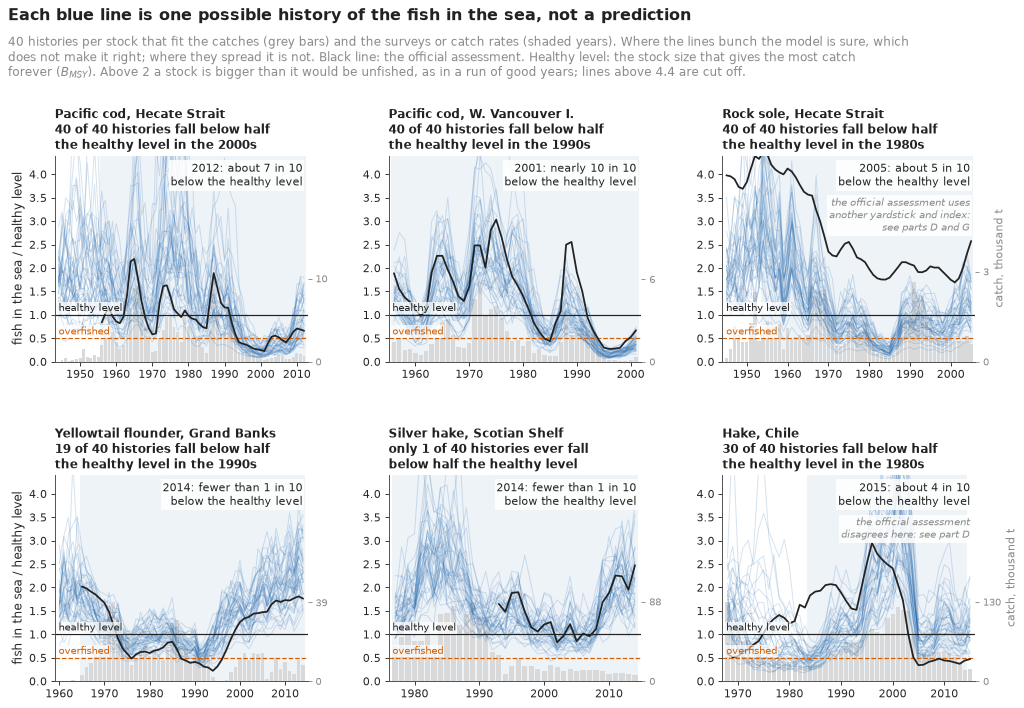

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the fits in part E.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

On 2 July 1992 Canada closed the northern cod fishery off Newfoundland. A stock that had
supported fishers for five centuries had fallen, in the official reconstruction, to about a
twentieth of the level that gives the largest sustainable catch, and some 30,000 people lost
their work. Hutchings & Myers (1994, *Can. J. Fish. Aquat. Sci.*) asked how the scientists had
missed it: catch rates in the commercial fishery held up while the fish shrank, because boats
kept finding the last dense schools. What is caught is not what is in the sea, and the gap
between them has to be modelled, with its uncertainty stated.

The oldest model for that gap is a **surplus-production model** (Schaefer 1954; Pella &
Tomlinson 1969). A stock of biomass $B$ grows logistically towards a carrying capacity $K$ at
intrinsic rate $r$, and the catch $C$ is taken out:

$$B_{t+1} = B_t + r B_t \left(1 - \frac{B_t}{K}\right) - C_t .$$

The growth term is the "interest" of a savings account. It is largest when the stock is at half
its unfished size, $B_{MSY} = K/2$, where it equals the **maximum sustainable yield**
$MSY = rK/4$; a fishing mortality above $F_{MSY} = r/2$ drains the account. The ratios
$B/B_{MSY}$ and $F/F_{MSY}$ are the coordinates of the **Kobe plot** that tuna commissions and
many national agencies use to report stock status.

We never see $B$. We see the catch, and an **index** (a research survey, or the catch per hour
of the fleet) assumed proportional to $B$ with noise. Meyer & Millar (1999, *Can. J. Fish. Aquat.
Sci.*) wrote this as a Bayesian **state-space model**: each year's biomass is a latent state with
process error (good and bad years for the fish), and the index observes it with observation
error. Punt & Hilborn (1997, *Reviews in Fish Biology and Fisheries*) made the case for Bayesian
assessment; JABBA (Winker, Carvalho & Kapur 2018, *Fisheries Research*) is a modern version. The
prior on $r$ is where biology enters: CMSY (Froese et al. 2017, *Fish and Fisheries*) turns
FishBase's resilience category into a range for $r$, and we start from the same ranges.

The data come from the **RAM Legacy Stock Assessment Database** (Ricard, Minto, Jensen & Baum
2012, *Fish and Fisheries*), which collects the inputs and outputs of formal assessments around
the world, so for 14 of our stocks there is an official answer to compare with. Those are usually
age-structured models with far more data: agreement is a check, not proof, and disagreement is a
question, not a verdict on either.

| part | question | tool |
|---|---|---|
| A | What do catches and an index look like? | Pacific cod, Hecate Strait; the surplus curve |
| B | What can a stock's history tell us? | a toy stock, one-way and two-way trips |
| C | How does one real stock fit? | centred free states, a prior check, two failures |
| D | What do 18 stocks share? | family priors for r, one process noise, official assessments |
| E | Below the healthy level, and still fished hard? | Kobe probabilities, one decisive noise |
| F | What if we only had the catches? | northern cod, catch-only refits |
| G | How do we explain it to everyone? | 40 possible histories, fish icons, an MSY band, a GIF |

## A · Catches, an index and a savings account

### The data

`tools/build_e114_ram.py` downloads the RAM v4.44 archive, reads its R tables once with Rscript,
and keeps one row per stock and year from the first to the last catch year. We kept stocks with
at least 25 years of catch and at least 15 years of an index, and the script checks each index
against the assessment's own biomass, where RAM has one, to catch copies: the Peruvian anchoveta's
"survey" equals its assessed biomass in every year, so it is not an independent index and the
anchoveta stays in the file only as a catch-only row. Each stock carries its FishBase resilience
and the matching range for $r$. Beyond the copy test the choice was a judgement made while
looking at the data: three more candidates (Greenland halibut, Gulf of St Lawrence cod, St Pierre
pollock) were left out after we saw how their index compared with the assessed biomass
(correlations 0.03 and 0.54, and one with nothing to compare), while Hecate Strait rock sole was
kept although its catch rate runs against the assessed biomass (correlation -0.17; its short
survey agrees better, 0.40).

In [3]:
data.describe("e114_ram_stocks")
RAM = data.load("e114_ram_stocks")
NICE = {
    "PCODHS": "Pacific cod, Hecate Strait", "PCODWCVANI": "Pacific cod, W. Vancouver Island",
    "PCOD5AB": "Pacific cod, Queen Charlotte Sound", "RSOLEHSTR": "Rock sole, Hecate Strait",
    "RSOLE5AB": "Rock sole, Queen Charlotte Sound", "YELL3LNO": "Yellowtail flounder, Grand Banks",
    "YELLGB": "Yellowtail flounder, Georges Bank",
    "WITFLOUN4RST": "Witch flounder, Gulf of St Lawrence",
    "SPHAKECH": "Hake, Chile", "SHAKE4VWX": "Silver hake, Scotian Shelf",
    "SHAKESGBMATL": "Silver hake, S. Georges Bank-Mid-Atlantic",
    "SHAKEGOMNGB": "Silver hake, Gulf of Maine", "REDFISHSPP3LN": "Redfish, Grand Banks",
    "NZSNAPNZ7": "Snapper, New Zealand (SNA 7)", "TREVALLYTRE7": "Trevally, New Zealand (TRE 7)",
    "NZLINGESE": "Ling, SE Australia", "BLSHARNPAC": "Blue shark, North Pacific",
    "WHAKE4T": "White hake, S. Gulf of St Lawrence", "ANCHOSA": "Anchovy, South Africa",
    "SARDSA": "Sardine, South Africa", "COD2J3KL": "Atlantic cod, northern (2J3KL)",
    "PANCHPERUNC": "Peruvian anchoveta"}
summ = (RAM.groupby("stockid")
        .agg(years=("year", lambda y: f"{y.min()}-{y.max()}"), cpue=("cpue", "count"),
             survey=("survey", "count"), official=("bdivbmsy", "count"), family=("family", "first"),
             resilience=("resilience", "first"), r_range=("r_lo", "first"), r_hi=("r_hi", "first"),
             max_catch_kt=("catch_t", lambda c: round(c.max() / 1e3, 1)), role=("role", "first")))
summ["r_range"] = [f"{a:.2f}-{b:.2f}" for a, b in zip(summ.r_range, summ.r_hi)]
print(summ.drop(columns="r_hi").sort_values(["role", "family"]).to_string())

e114_ram_stocks: One row per stock and year from the first to the last catch year (1,278 rows, 22 stocks): stockid, year, catch_t (total catch TCbest, tonnes), cpue and survey (RAM's preferred abundance indices, units in cpue_units / survey_units), bdivbmsy and udivumsy (the assessment's B/Bmsy and U/Umsy), tb_t (assessment total biomass, tonnes); stock columns repeated per row: stocklong, commonname, scientificname, family, region, assessorid, assessyear, role ('index': 20 finfish stocks with an index of >= 15 years; 'catch_only': northern cod COD2J3KL and Peruvian anchoveta PANCHPERUNC, whose RAM survey series equals the assessment's own biomass and is dropped), resilience (FishBase), r_lo, r_hi (Froese et al. 2017 prior range of r).
  source: RAM Legacy Stock Assessment Database v4.44 (Ricard, Minto, Jensen & Baum 2012, Fish and Fisheries 13:380-398), Zenodo DOI 10.5281/zenodo.2542919, licence CC BY 4.0; retrieved 2026-11-05. Resilience categories from FishBase species summaries (re

Twenty stocks have an index, from 18 years (blue shark) to 57 (Pacific cod in Hecate Strait and
Queen Charlotte Sound), and fourteen also have the assessment's B/B<sub>MSY</sub>. They span
eleven families; cod (Gadidae), flatfish (Pleuronectidae) and hake (Merlucciidae) have three to
five stocks each, the rest one. FishBase calls most of them "low" resilience, with $r$ between
0.05 and 0.5 a year, and the four *Merluccius* hakes, witch flounder and the two South African
small pelagics "medium" (0.2-0.8). These two swing with ocean conditions more than with fishing,
a story a surplus-production model tells badly; they caused most of the divergences in a
20-stock fit, so the main model uses the other 18 and leaves them for "Try it yourself".

### One stock: Pacific cod in Hecate Strait

Hecate Strait lies between the Haida Gwaii islands and the mainland of British Columbia. Its
Pacific cod have been fished since the 1940s, with a commercial catch rate (kg per hour of
trawling) from 1956 and a research survey for 1984-1994.

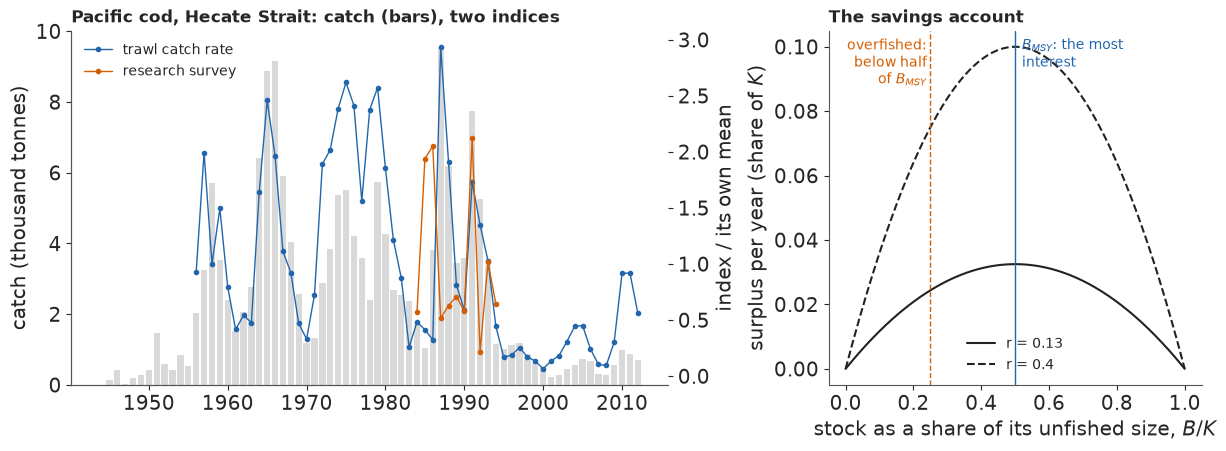

In [4]:
def stock_rows(sid):
    return RAM[RAM.stockid == sid].sort_values("year").reset_index(drop=True)


g = stock_rows("PCODHS")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), width_ratios=[1.6, 1])
ax.bar(g.year, g.catch_t / 1e3, color=LIGHT, width=0.8)
ax.set_ylabel("catch (thousand tonnes)")
axr = ax.twinx()
for col, c, lab in (("cpue", HI, "trawl catch rate"), ("survey", LO, "research survey")):
    ok = g[col].notna()
    axr.plot(g.year[ok], g[col][ok] / g[col][ok].mean(), "o-", color=c, ms=3, lw=1, label=lab)
axr.set_ylabel("index / its own mean")
axr.grid(False)
axr.legend(loc="upper left", fontsize=10)
ax.set_title("Pacific cod, Hecate Strait: catch (bars), two indices", loc="left", fontsize=12)
P_ = np.linspace(0, 1, 200)
for rr, ls in ((0.13, "-"), (0.4, "--")):
    ax2.plot(P_, rr * P_ * (1 - P_), color=INK, ls=ls, label=f"r = {rr}")
ax2.axvline(0.5, color=HI, lw=1)
ax2.axvline(0.25, color=LO, lw=1, ls="--")
ax2.text(0.52, 0.103, "$B_{MSY}$: the most\ninterest", color=HI, fontsize=10, va="top")
ax2.text(0.24, 0.103, "overfished:\nbelow half\nof $B_{MSY}$", color=LO, fontsize=10, ha="right",
         va="top")
ax2.set_xlabel("stock as a share of its unfished size, $B/K$")
ax2.set_ylabel("surplus per year (share of $K$)")
ax2.legend(loc="lower center", fontsize=10)
ax2.set_title("The savings account", loc="left", fontsize=12);

The catch peaked twice, at about 9,000 t in the mid-1960s and 9,500 t in 1987, and fell to a
few hundred tonnes after 2000. The catch rate peaks in the 1970s and is lowest around 2000, with
year-to-year jumps of a factor of two: observation error. The eleven-year survey does not
obviously agree with it, and for 1944-1955 there is no index at all.

The right panel is the savings account: the surplus is a parabola in $B/K$ that peaks at half the
unfished size whatever $r$ is; $r$ only sets the height. The dashed line is the usual
"overfished" threshold, half of $B_{MSY}$.

## B · A toy stock: what a one-way trip cannot tell

### Two histories with a known truth

Before a real stock, a simulated one with $r = 0.4$, $K = 1{,}000$ t and so $MSY = 100$ t, an
index with catchability $q = 0.001$ and 15% observation noise, and a little process noise. In
the **one-way trip** the catch rises steadily from 10% to 150% of MSY over 40 years, and the
stock declines from $K$ to about 40% of it. In the **two-way trip** the catch rises to 170%
of MSY over 20 years and is then cut to 40%, so the stock falls and recovers. Hilborn & Walters
(1992, *Quantitative Fisheries Stock Assessment*) made the point this toy illustrates: data from
a fishery that has only ever gone down tell you little about how it would come back.

In [5]:
R_TRUE, K_TRUE, Q_TRUE, T_TOY = 0.4, 1000.0, 0.001, 40
MSY_TRUE = R_TRUE * K_TRUE / 4
tt = np.arange(T_TOY)
TRIPS = {"one-way trip": MSY_TRUE * (0.1 + 1.4 * tt / (T_TOY - 1)),
         "two-way trip": np.where(tt < 20, MSY_TRUE * (0.1 + 1.6 * tt / 19), 0.4 * MSY_TRUE)}
toy_rng = np.random.default_rng(1140)


def simulate(C, gen, sp=0.05, so=0.15):
    P = np.empty(len(C))
    P[0] = 1.0
    for k in range(1, len(C)):
        f = P[k - 1] + R_TRUE * P[k - 1] * (1 - P[k - 1]) - C[k - 1] / K_TRUE
        P[k] = max(f, 0.01) * np.exp(sp * gen.normal())
    return P, Q_TRUE * K_TRUE * P * np.exp(so * gen.normal(size=len(C)))


TOY = {k: (C,) + simulate(C, toy_rng) for k, C in TRIPS.items()}
for k, (C, P, I) in TOY.items():
    print(f"{k}: B/K from {P[0]:.2f} to a low of {P.min():.2f}, ending at {P[-1]:.2f}")

one-way trip: B/K from 1.00 to a low of 0.40, ending at 0.40
two-way trip: B/K from 1.00 to a low of 0.32, ending at 0.86


### A fit with observation error only

The simplest fit, and the one fisheries scientists used for decades, ignores process error:
given $r$, $K$ and a start at $K$, the dynamics are deterministic, and only the index is noisy,
$\log I_t \sim N(\log q + \log B_t, \sigma_o)$. The recursion runs in `pytensor.scan`, and a
smooth floor $\epsilon \,\mathrm{softplus}(f/\epsilon)$ keeps the stock positive when a draw of
$(r, K)$ makes the catch larger than the fish. The priors are deliberately vague: $\log r \sim
N(\log 0.4, 1)$ and $K$ around five times the largest catch with a log sd of 1.

In [6]:
def toy_fit(C, I, seed=1):
    cmax = C.max()
    with pm.Model() as m:
        log_r = pm.Normal("log_r", np.log(0.4), 1.0)
        log_K = pm.Normal("log_K", np.log(5 * cmax), 1.0)
        r, K = pt.exp(log_r), pt.exp(log_K)

        def step(c, p, r, K):
            f = p + r * p * (1 - p) - c / K
            return 0.01 * pt.softplus(f / 0.01)

        Ps = pytensor.scan(step, sequences=[pt.as_tensor(C[:-1])],
                           outputs_info=[pt.constant(1.0, dtype="float64")],
                           non_sequences=[r, K], return_updates=False)
        P_all = pt.concatenate([pt.ones(1), Ps])
        lq = pm.Normal("log_qK", np.log(I).mean() - np.log(0.5), 2.0)
        so = pm.LogNormal("sigma_o", np.log(0.2), 0.5)
        pm.Normal("I", lq + pt.log(P_all), so, observed=np.log(I))
        return pm.sample(random_seed=seed, progressbar=False, target_accept=0.9)


t0 = time.time()
TOY_POST = {}
for k, (C, P, I) in TOY.items():
    idt = toy_fit(C, I)
    lr = idt.posterior["log_r"].values.ravel()
    lk = idt.posterior["log_K"].values.ravel()
    sm = az.summary(idt, var_names=["log_r", "log_K"], round_to=4)
    q_r, q_k, q_m = (np.quantile(v, [0.055, 0.5, 0.945])
                     for v in (np.exp(lr), np.exp(lk), np.exp(lr + lk) / 4))
    TOY_POST[k] = (lr, lk)
    print(f"{k}: divergences {int(idt.sample_stats['diverging'].sum())}, "
          f"max r_hat {sm.r_hat.max():.3f}, min ESS {sm.ess_bulk.min():.0f}, "
          f"corr(log r, log K) {np.corrcoef(lr, lk)[0, 1]:.2f}\n"
          f"   r {q_r[1]:.2f} ({q_r[0]:.2f}-{q_r[2]:.2f}), K {q_k[1]:,.0f} ({q_k[0]:,.0f}-"
          f"{q_k[2]:,.0f}), MSY {q_m[1]:.0f} ({q_m[0]:.0f}-{q_m[2]:.0f});  truth r 0.4, K 1,000, "
          f"MSY 100")
TIMES["toy"] = time.time() - t0

one-way trip: divergences 160, max r_hat 1.012, min ESS 186, corr(log r, log K) -0.99
   r 0.35 (0.10-1.08), K 1,213 (467-2,930), MSY 107 (69-128);  truth r 0.4, K 1,000, MSY 100


two-way trip: divergences 0, max r_hat 1.006, min ESS 727, corr(log r, log K) -0.98
   r 0.40 (0.33-0.49), K 971 (837-1,130), MSY 97 (91-103);  truth r 0.4, K 1,000, MSY 100


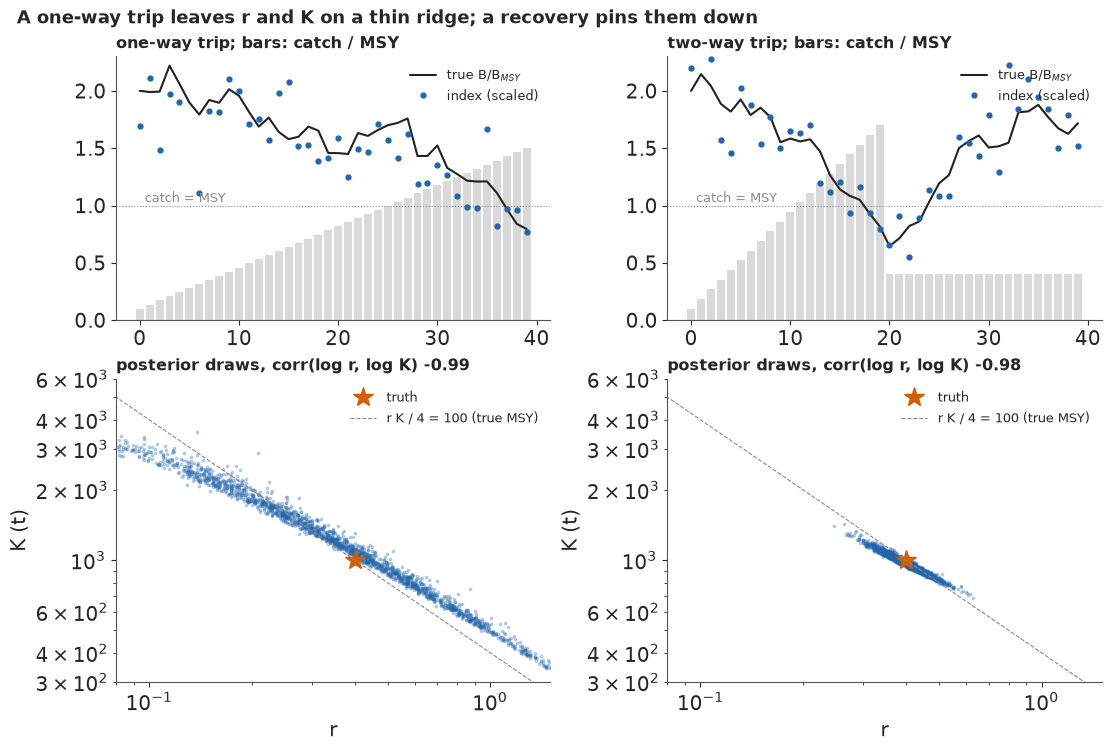

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7.4), height_ratios=[1, 1.15])
for j, (k, (C, P, I)) in enumerate(TOY.items()):
    a = axs[0, j]
    a.bar(tt, C / MSY_TRUE, color=LIGHT, width=0.8)
    a.axhline(1, color=MUTED, lw=0.8, ls=":")
    a.text(0.5, 1.03, "catch = MSY", color=MUTED, fontsize=9.5)
    a.plot(tt, 2 * P, color=INK, lw=1.5, label="true B/B$_{MSY}$")
    a.plot(tt, 2 * I / (Q_TRUE * K_TRUE), "o", color=HI, ms=3.5, label="index (scaled)")
    a.set_ylim(0, 2.3)
    a.set_title(f"{k}; bars: catch / MSY", loc="left", fontsize=11.5)
    a.legend(loc="upper right", fontsize=9.5)
    lr, lk = TOY_POST[k]
    b = axs[1, j]
    b.scatter(np.exp(lr[::2]), np.exp(lk[::2]), s=3, alpha=0.25, color=HI)
    b.plot(R_TRUE, K_TRUE, "*", color=LO, ms=15, label="truth")
    rg = np.geomspace(0.05, 3, 50)
    b.plot(rg, 4 * MSY_TRUE / rg, color=MUTED, lw=0.8, ls="--", label="r K / 4 = 100 (true MSY)")
    b.set_xscale("log")
    b.set_yscale("log")
    b.set_xlim(0.08, 1.5)
    b.set_ylim(300, 6000)
    b.set_xlabel("r")
    b.set_ylabel("K (t)")
    b.legend(loc="upper right", fontsize=9.5)
    b.set_title(f"posterior draws, corr(log r, log K) {np.corrcoef(lr, lk)[0, 1]:.2f}",
                loc="left", fontsize=11.5)
fig.suptitle("A one-way trip leaves r and K on a thin ridge; a recovery pins them down",
             x=0.01, ha="left", fontsize=13);

On the one-way trip the posterior is a long, thin banana: $\log r$ and $\log K$ are correlated
at $-0.99$, and $r$ could be anything from 0.1 to 1.1 a year, with $K$ moving the other way from
about 470 to 2,900 t. The data fix one combination, roughly the surplus the stock produced while
it declined (MSY 69-128 t), and say almost nothing about whether that is a fast growth rate on a
small stock or a slow one on a big stock. The 160 divergences come from the ends of the banana,
where it bends and narrows.

On the two-way trip the recovery after the cut is the missing experiment: how fast the stock came
back measures $r$, and the ridge shrinks to a short segment around the truth ($r$ 0.33-0.49, MSY
91-103 t, no divergences). Real fisheries are mostly one-way trips, so information about $r$ has
to come from biology and from other stocks of the same kind. That is what part D does.

## C · One real stock in PyMC

### The state-space model

For stock $s$ we work with the **depletion** $P_{st} = B_{st}/K_s$ and with catches divided by
the stock's largest catch $\bar C_s$, so that $K_s$ is in units of the largest catch and every
stock has the same scale. The model, after Meyer & Millar (1999), is

$$f_{st} = P_{s,t-1} + r_s P_{s,t-1}(1 - P_{s,t-1}) - C_{s,t-1}/K_s, \qquad
\log P_{st} \sim N\big(\log \tilde f_{st},\ \sigma_p\big),$$

$$\log I_{it} \sim N\big(\log (qK)_i + \log P_{s(i),t},\ \sigma_{o,i}\big),$$

where $\tilde f = \epsilon\,\mathrm{softplus}(f/\epsilon)$ is a smooth floor at about
$\epsilon = 1\%$ of $K$, and $i$ runs over the index series (Pacific cod in Hecate Strait has
two). A stock cannot lose more fish than it has, so a penalty
$-\sum \mathrm{softplus}\big((0.02 - f_{st})/0.005\big)$ removes draws in which the catch would
take the stock below 2% of $K$; without it the floor alone would let a tiny $K$ explain any
catch. The priors:

- $\log P_{s1} \sim N(\log 0.8, 0.3)$: lightly fished when the record starts, an assumption that
  flatters records starting after heavy fishing (Scotian Shelf silver hake from 1977, after the
  distant-water fleets; Chilean hake's catches here from 1968);
- $\log K_s \sim N(\log 5, 0.8)$ in units of the largest catch: about 1.4 to 18 times it (89%);
- $\log r_s \sim N(m_s, w_s)$ with $m_s$ the log midpoint of the FishBase-CMSY range and $w_s$ a
  quarter of its log width, so the range is a 95% interval (part D keeps the centre and changes
  the width);
- $\sigma_p \sim \mathrm{LogNormal}(\log 0.1, 0.5)$, $\sigma_{o,i} \sim
  \mathrm{LogNormal}(\log 0.25, 0.5)$, and $\log(qK)_i$ vague around the index's mean.

The states $\log P_{st}$ are **free parameters** (`pm.Flat`), and the process and initial
densities enter as `pm.Potential` terms: the **centred** form. The **non-centred** form, usually
recommended for hierarchical models, pushes standardised innovations through a `scan`; we try it
too. One helper flattens any list of stocks into stock-year arrays, and one builds the model.

In [8]:
def prep(stocks, source=RAM, use_index=True, multi_only=True):
    """Flatten stock-years for several stocks; catches in units of each stock's largest catch."""
    st, years, C, first, prev, cmax, m_r, s_r, fam = [], [], [], [], [], [], [], [], []
    obs_state, obs_ser, logI, ser_name, ser_m, ser_stock = [], [], [], [], [], []
    off = 0
    for s, sid in enumerate(stocks):
        g = source[source.stockid == sid].sort_values("year").reset_index(drop=True)
        T = len(g)
        cmax.append(g.catch_t.max())
        st += [s] * T
        years += list(g.year)
        C += list(g.catch_t / g.catch_t.max())
        first.append(off)
        prev += list(range(off, off + T - 1))
        lo, hi = g.r_lo.iloc[0], g.r_hi.iloc[0]
        m_r.append(0.5 * (np.log(lo) + np.log(hi)))
        s_r.append((np.log(hi) - np.log(lo)) / 4)
        fam.append(g.family.iloc[0])
        for kind in ("cpue", "survey") if use_index else ():
            ok = (g[kind].notna() & (g[kind] > 0)).to_numpy()
            if ok.sum() >= 5:
                li = np.log(g[kind][ok].to_numpy())
                obs_state += list(off + np.where(ok)[0])
                obs_ser += [len(ser_name)] * int(ok.sum())
                logI += list(li)
                ser_name.append(f"{sid}:{kind}")
                ser_m.append(li.mean())
                ser_stock.append(s)
        off += T
    if multi_only:  # family effects only for families with two or more stocks
        fam = [f if fam.count(f) >= 2 else "(single)" for f in fam]
    fams = sorted(set(fam))
    st = np.array(st)
    first = np.array(first)
    last = np.r_[first[1:] - 1, off - 1]
    return dict(stocks=list(stocks), S=len(stocks), N=off, st=st, years=np.array(years),
                C=np.array(C), first=first, last=last, rest=np.setdiff1d(np.arange(off), first),
                prev=np.array(prev), cmax=np.array(cmax), obs_state=np.array(obs_state, int),
                obs_ser=np.array(obs_ser, int), logI=np.array(logI), ser_name=ser_name,
                ser_m=np.array(ser_m), ser_stock=np.array(ser_stock, int), m_r=np.array(m_r),
                s_r=np.array(s_r), fam_names=fams, fam=np.array([fams.index(f) for f in fam]))


def ss_model(d, *, hier=False, sigma_p="stock", sp_mu=np.log(0.1), sp_sd=0.5, k_mu=np.log(5.0),
             k_sd=0.8, eps=0.01, pen=0.005, floor=0.02, end_prior=None):
    """Schaefer state-space model with centred free states (Meyer & Millar 1999).

    sigma_p: "stock" (one per stock), "pooled" (one for all) or a number (fixed).
    end_prior: (lo, hi) range for the final depletion B/K, imposed as a steep wall (CMSY's filter).
    """
    coords = {"stock": d["stocks"], "state": np.arange(d["N"]), "series": d["ser_name"],
              "family": d["fam_names"]}
    st, prev, rest, first = d["st"], d["prev"], d["rest"], d["first"]
    with pm.Model(coords=coords) as m:
        if hier:
            sigma_fam = pm.HalfNormal("sigma_fam", 0.4)
            tau_r = pm.HalfNormal("tau_r", 0.4)
            w = pm.Normal("w_fam", 0, 1, dims="family")
            z = pm.Normal("z_r", 0, 1, dims="stock")
            fe = sigma_fam * w
            if "(single)" in d["fam_names"]:
                fe = pt.set_subtensor(fe[d["fam_names"].index("(single)")], 0.0)
            log_r = pm.Deterministic("log_r", d["m_r"] + fe[d["fam"]] + tau_r * z, dims="stock")
        else:
            log_r = pm.Normal("log_r", d["m_r"], d["s_r"], dims="stock")
        r = pm.Deterministic("r", pt.exp(log_r), dims="stock")
        log_K = pm.Normal("log_K", k_mu, k_sd, dims="stock")
        K = pt.exp(log_K)
        if sigma_p == "pooled":
            sp = pm.LogNormal("sigma_p", sp_mu, sp_sd) * pt.ones(d["S"])
        elif sigma_p == "stock":
            sp = pm.LogNormal("sigma_p", sp_mu, sp_sd, dims="stock")
        else:
            sp = pt.as_tensor(np.full(d["S"], float(sigma_p)))
        logP = pm.Flat("logP", dims="state")
        Pp = pt.exp(logP)[prev]
        f = Pp + r[st[rest]] * Pp * (1 - Pp) - d["C"][prev] / K[st[rest]]
        f_pos = eps * pt.softplus(f / eps)
        pm.Potential("start", pm.logp(pm.Normal.dist(np.log(0.8), 0.3), logP[first]).sum())
        pm.Potential("process", pm.logp(pm.Normal.dist(pt.log(f_pos), sp[st[rest]]),
                                        logP[rest]).sum())
        pm.Potential("feasible", -pt.softplus((floor - f) / pen).sum())
        if end_prior is not None:
            lo, hi = np.log(end_prior[0]), np.log(end_prior[1])
            lpl = logP[d["last"]]  # log-density falls by 20 per unit of log B/K outside the range
            pm.Potential("end_prior", (-pt.softplus((lpl - hi) / 0.05)
                                       - pt.softplus((lo - lpl) / 0.05)).sum())
        if d["ser_name"]:
            lq = pm.Normal("log_qK", d["ser_m"] - np.log(0.5), 2.0, dims="series")
            sigma_o = pm.LogNormal("sigma_o", np.log(0.25), 0.5, dims="series")
            pm.Normal("logI", lq[d["obs_ser"]] + logP[d["obs_state"]], sigma_o[d["obs_ser"]],
                      observed=d["logI"])
    return m


def sample(m, d, seed, ta=0.9, **kw):
    t0 = time.time()
    idata = pm.sample(model=m, random_seed=seed, target_accept=ta, progressbar=False,
                      initvals={"logP": np.full(d["N"], np.log(0.5))}, **kw)
    return idata, time.time() - t0


def draws(idata, v):
    """Posterior draws as an array (draw, ...), chains stacked."""
    return idata.posterior[v].stack(s=("chain", "draw")).transpose("s", ...).values


def status(idata, d):
    """B/B_MSY = 2P and F/F_MSY = (C/B)/(r/2) for every stock-year and draw."""
    P = np.exp(draws(idata, "logP"))
    r, K = draws(idata, "r")[:, d["st"]], np.exp(draws(idata, "log_K"))[:, d["st"]]
    return 2 * P, d["C"][None, :] / (K * P) / (r / 2)


def report(idata, d, names, label, secs):
    div = int(idata.sample_stats["diverging"].sum())
    sm = pd.concat([az.summary(idata, var_names=[v], round_to=4) for v in names])
    print(f"{label}: {secs:.0f} s, {div} divergences of {idata.posterior.sizes['draw'] * 4:,}, "
          f"max r_hat {sm.r_hat.max():.3f}, min bulk ESS {sm.ess_bulk.min():.0f}, min tail ESS "
          f"{sm.ess_tail.min():.0f} (warm-up {idata.posterior.attrs.get('tuning_steps')})")
    return div


D1 = prep(["PCODHS"], multi_only=False)
print(f"{D1['N']} states, {len(D1['logI'])} index values in {len(D1['ser_name'])} series; "
      f"prior r 95% range {np.exp(D1['m_r'][0] - 2 * D1['s_r'][0]):.2f}-"
      f"{np.exp(D1['m_r'][0] + 2 * D1['s_r'][0]):.2f}")

69 states, 68 index values in 2 series; prior r 95% range 0.05-0.50


### The prior, checked by simulation

Because the dynamics are potentials, PyMC cannot draw a prior predictive for us, so we simulate
it in NumPy: draw $r$, $K$, $\sigma_p$ and the start from their priors, run Pacific cod's real
catches through the dynamics, and look at the biomass paths. A sensible prior should allow
stocks from barely touched to heavily fished, and should not make most stocks collapse under
the catches that were actually taken.

K in tonnes, 89% prior range: 13,138-162,694 (largest catch 9,540 t)
prior paths in which the catch would empty the stock: 71% (the feasibility penalty removes them)
surviving paths: final B/B_MSY median 1.83, 89% 0.93-2.48


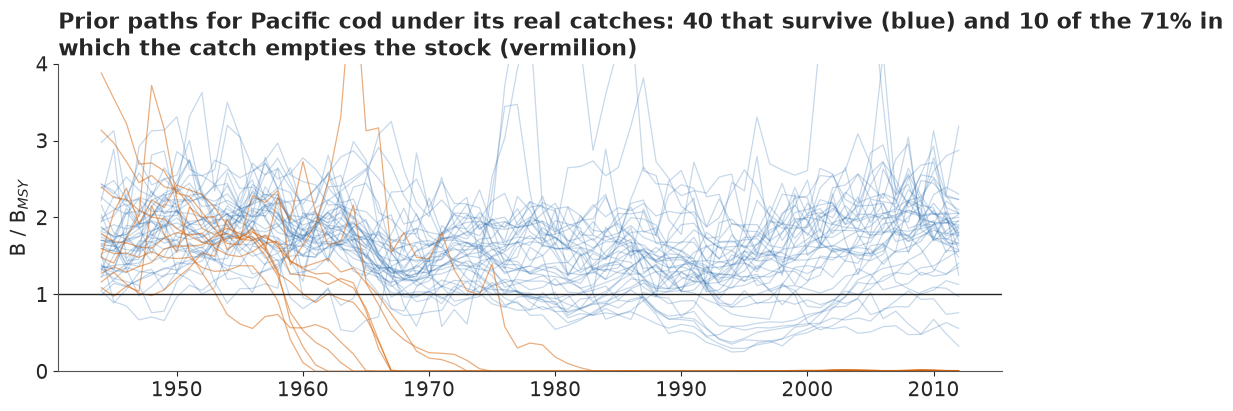

In [9]:
def prior_paths(d, n, gen, eps=0.01, k_mu=np.log(5.0), k_sd=0.8):
    r = np.exp(gen.normal(d["m_r"][0], d["s_r"][0], n))
    K = np.exp(gen.normal(k_mu, k_sd, n))
    sp = np.exp(gen.normal(np.log(0.1), 0.5, n))
    P = np.empty((n, d["N"]))
    P[:, 0] = np.exp(gen.normal(np.log(0.8), 0.3, n))
    fmin = np.full(n, np.inf)
    for t in range(1, d["N"]):
        f = P[:, t - 1] + r * P[:, t - 1] * (1 - P[:, t - 1]) - d["C"][t - 1] / K
        fmin = np.minimum(fmin, f)
        P[:, t] = eps * np.logaddexp(0, f / eps) * np.exp(sp * gen.normal(size=n))
    return 2 * P, K, fmin


BB_PRIOR, K_PRIOR, FMIN = prior_paths(D1, 4000, np.random.default_rng(7))
crash = FMIN < 0.02
print(f"K in tonnes, 89% prior range: {np.quantile(K_PRIOR, 0.055) * D1['cmax'][0]:,.0f}-"
      f"{np.quantile(K_PRIOR, 0.945) * D1['cmax'][0]:,.0f} (largest catch "
      f"{D1['cmax'][0]:,.0f} t)")
print(f"prior paths in which the catch would empty the stock: {crash.mean():.0%} "
      f"(the feasibility penalty removes them)")
print(f"surviving paths: final B/B_MSY median {np.median(BB_PRIOR[~crash, -1]):.2f}, "
      f"89% {np.quantile(BB_PRIOR[~crash, -1], 0.055):.2f}-"
      f"{np.quantile(BB_PRIOR[~crash, -1], 0.945):.2f}")
fig, ax = plt.subplots(figsize=(10, 4))
yrs1 = D1["years"]
for i in np.where(~crash)[0][:40]:
    ax.plot(yrs1, BB_PRIOR[i], color=HI, alpha=0.25, lw=0.9)
for i in np.where(crash)[0][:10]:
    ax.plot(yrs1, BB_PRIOR[i], color=LO, alpha=0.5, lw=0.9)
ax.axhline(1, color=INK, lw=1)
ax.set_ylim(0, 4)
ax.set_ylabel("B / B$_{MSY}$")
ax.set_title(wrap(f"Prior paths for Pacific cod under its real catches: 40 that survive (blue) "
                  f"and 10 of the {crash.mean():.0%} in which the catch empties the stock "
                  f"(vermilion)", 95), loc="left");

The prior allows $K$ from about 1.4 to 18 times the largest catch (13,000 to 163,000 t in this
simulation), yet about 70% of the prior draws cannot support the catches that were taken: with
a growth rate near 0.16, a stock five times the largest catch has an MSY of only a fifth of it,
and Pacific cod was fished near its largest catch for years.

The prior that reaches the data is the surviving 30%, and it has an opinion: those paths mostly
end above the healthy level (final B/B<sub>MSY</sub> median about 1.8, 89% range 0.9-2.5),
because a stock big enough to survive the catches was never heavily depleted by them. An index
can overrule that opinion. Without one, in part F, it is the answer.

### Failure 1: non-centred states

The usual advice for a hierarchical model with a poorly identified scale is to **non-centre**:
sample standardised innovations $e_t \sim N(0, 1)$ and build the states as
$\log P_t = \log \tilde f_t + \sigma_p e_t$ in a `scan`. We try that first, with a short run.

In [10]:
def nc_model(d, eps=0.01):
    """Non-centred single-stock version: innovations through a scan recursion."""
    T = d["N"]
    with pm.Model() as m:
        log_r = pm.Normal("log_r", d["m_r"][0], d["s_r"][0])
        r = pm.Deterministic("r", pt.exp(log_r))
        log_K = pm.Normal("log_K", np.log(5.0), 0.8)
        K = pt.exp(log_K)
        sp = pm.LogNormal("sigma_p", np.log(0.1), 0.5)
        e0 = pm.Normal("e0", 0, 1)
        e = pm.Normal("e", 0, 1, shape=T - 1)

        def step(e_t, c_t, lp, r, K, sp):
            p = pt.exp(lp)
            f = p + r * p * (1 - p) - c_t / K
            return pt.log(eps * pt.softplus(f / eps)) + sp * e_t, f

        lps, fs = pytensor.scan(step, sequences=[e, pt.as_tensor(d["C"][:-1])],
                                outputs_info=[np.log(0.8) + 0.3 * e0, None],
                                non_sequences=[r, K, sp], return_updates=False)
        logP = pm.Deterministic("logP", pt.concatenate([(np.log(0.8) + 0.3 * e0)[None], lps]))
        pm.Potential("feasible", -pt.softplus((0.02 - fs) / 0.005).sum())
        lq = pm.Normal("log_qK", d["ser_m"] - np.log(0.5), 2.0, shape=len(d["ser_name"]))
        so = pm.LogNormal("sigma_o", np.log(0.25), 0.5, shape=len(d["ser_name"]))
        pm.Normal("logI", lq[d["obs_ser"]] + logP[d["obs_state"]], so[d["obs_ser"]],
                  observed=d["logI"])
    return m


t0 = time.time()
id_nc = pm.sample(model=nc_model(D1), random_seed=RANDOM_SEED, target_accept=0.95, tune=400,
                  draws=500, progressbar=False)
DIV_NC = report(id_nc, D1, ["log_r", "log_K", "sigma_p"], "non-centred, Pacific cod",
                time.time() - t0)
TIMES["non-centred"] = time.time() - t0
del id_nc

non-centred, Pacific cod: 44 s, 194 divergences of 2,000, max r_hat 1.556, min bulk ESS 7, min tail ESS 7 (warm-up 400)


About one transition in ten diverges, r_hat reaches 1.6 and the worst bulk ESS is 7: the chains
have not mixed. The reason is the one E46 met with a chaotic map. Every state depends on every
earlier innovation through the nonlinear dynamics, so a small change in $r$ or an early $e_t$
moves the whole path, while the index pins each $\log P_t$ tightly: a curved, narrow tube in the
innovations that no single step size can follow. Non-centring helps when the data are weak about
each state; here they are strong.

### The centred fit

In [11]:
id1, secs = sample(ss_model(D1), D1, RANDOM_SEED, ta=0.95)
DIV_C1 = report(id1, D1, ["log_r", "log_K", "sigma_p", "sigma_o", "logP"],
                "centred, Pacific cod", secs)
TIMES["centred"] = secs
dv = id1.sample_stats["diverging"].stack(s=("chain", "draw")).values
sp1 = draws(id1, "sigma_p").ravel()
print(f"sigma_p: median {np.median(sp1):.3f}; in divergent draws "
      f"{np.median(sp1[dv]) if dv.any() else float('nan'):.3f}")
print(f"r: prior median {np.exp(D1['m_r'][0]):.2f}, posterior median "
      f"{np.median(draws(id1, 'r')):.2f}")

centred, Pacific cod: 3 s, 28 divergences of 4,000, max r_hat 1.071, min bulk ESS 40, min tail ESS 55 (warm-up 400)
sigma_p: median 0.400; in divergent draws 0.523
r: prior median 0.16, posterior median 0.15


With free states the same stock samples in a few seconds, and the worst r_hat drops from 1.6 to
about 1.07. That is better, not clean: a few dozen divergences remain, the lowest ESS is about 40,
and the divergent draws have a **larger** process noise than the rest (median about 0.52 against
0.40). This is not the familiar funnel at a scale near zero. When $\sigma_p$ is large, the 12
years before the first index (1944-1955) are free to wander, and the posterior gets a thin,
wide-spreading region that the sampler cannot enter smoothly. We will come back to it.

The fit should first reproduce what it was fitted to. The posterior predictive for each index is
the fitted state times the catchability with fresh observation noise.

PCODHS:cpue: 100% inside; sigma_o median 0.40
PCODHS:survey: 91% inside; sigma_o median 0.72


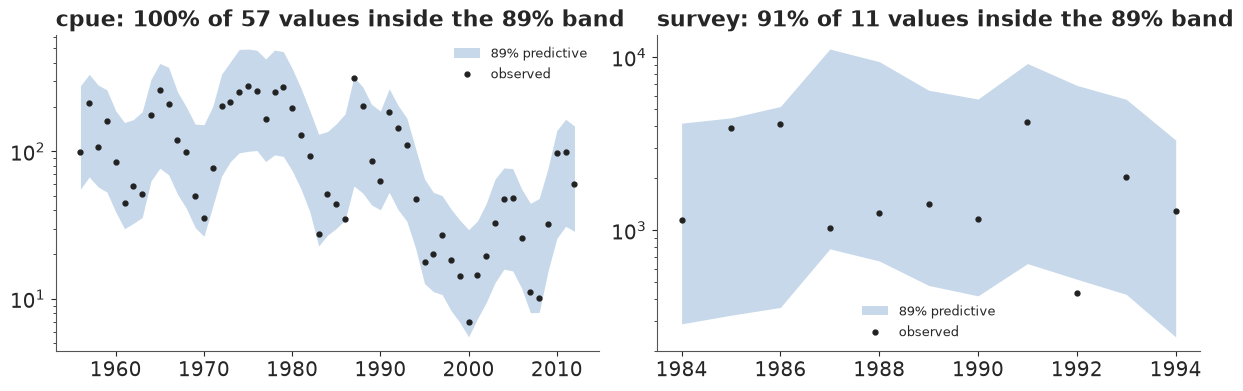

In [12]:
lp1, lq1, so1 = draws(id1, "logP"), draws(id1, "log_qK"), draws(id1, "sigma_o")
pp_rng = np.random.default_rng(3)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (a, nm) in enumerate(zip(axs, D1["ser_name"])):
    sel = D1["obs_ser"] == i
    stt = D1["obs_state"][sel]
    rep = lq1[:, [i]] + lp1[:, stt] + so1[:, [i]] * pp_rng.normal(size=(len(lq1), sel.sum()))
    lo_, hi_ = np.quantile(rep, [0.055, 0.945], axis=0)
    a.fill_between(D1["years"][stt], np.exp(lo_), np.exp(hi_), color=HI, alpha=0.25, lw=0,
                   label="89% predictive")
    a.plot(D1["years"][stt], np.exp(D1["logI"][sel]), "o", color=INK, ms=3.5, label="observed")
    inside = ((D1["logI"][sel] >= lo_) & (D1["logI"][sel] <= hi_)).mean()
    a.set_yscale("log")
    a.legend(fontsize=9.5)
    a.set_title(f"{nm.split(':')[1]}: {inside:.0%} of {sel.sum()} values inside the 89% band",
                loc="left")
    print(f"{nm}: {inside:.0%} inside; sigma_o median {np.median(so1[:, i]):.2f}")

All 57 catch-rate values and 10 of the 11 survey values sit inside their 89% predictive bands,
if anything too good. The catch rate gets an observation sd of about 0.4 and the short survey
about 0.7: the survey disagrees with the catch rate in the late 1980s and the model trusts the
longer series. This check cannot fail very badly in a state-space model, because the states can
follow the index wherever the process noise allows.

The data barely move $r$ (posterior median 0.15, prior 0.16): like the toy's one-way trip, the
index says how the stock went down and partly back up, not how fast it grows.

### Failure 2: a long record with no index

Georges Bank yellowtail flounder has 80 years of catch (from 1935) but a survey only from 1987,
so for half a century the states are tied only to the catches and the dynamics. Fitted alone with
its own process noise:

In [13]:
DG = prep(["YELLGB"], multi_only=False)
idg, secs = sample(ss_model(DG), DG, RANDOM_SEED, ta=0.95)
DIV_G = report(idg, DG, ["log_r", "log_K", "sigma_p", "logP"], "Georges Bank yellowtail alone",
               secs)
dv = idg.sample_stats["diverging"].stack(s=("chain", "draw")).values
spg = draws(idg, "sigma_p").ravel()
print(f"sigma_p: median {np.median(spg):.3f}, 89% {np.quantile(spg, 0.055):.3f}-"
      f"{np.quantile(spg, 0.945):.3f}; in divergent draws {np.median(spg[dv]):.3f}")
TIMES["yellowtail alone"] = secs
del idg

Georges Bank yellowtail alone: 5 s, 298 divergences of 4,000, max r_hat 1.024, min bulk ESS 270, min tail ESS 313 (warm-up 400)
sigma_p: median 0.540, 89% 0.377-0.737; in divergent draws 0.682


About 300 divergences. The process sd comes out at about 0.54 (89% 0.38-0.74), more than for
Pacific cod, and the divergent draws again sit at its upper end (median about 0.68), where five
decades of index-free states can roam. One stock cannot tell how big its own process noise is
when most of its states are unobserved; part D lets the stocks share it.

## D · Eighteen stocks, shared biology

### What the stocks share

Two things are pooled. First, **growth**. The prior for each stock's $\log r$ is centred at the
midpoint of its resilience range, and stocks of the same family share a family effect:

$$\log r_s = m_s + \sigma_{fam}\, w_{f(s)} + \tau_r\, z_s, \qquad w, z \sim N(0, 1),\quad
\sigma_{fam}, \tau_r \sim \mathrm{HalfNormal}(0.4).$$

Only cod, flatfish and hake have more than one stock here. A family effect for a family with a
single stock cannot be told apart from that stock's own effect: the data see only their sum, and
in our trial fits that unidentified pair added divergences. So the six single-stock families get
no family term.

Second, **process noise**. Good and bad years differ between stocks, but their typical size may
be similar enough for one shared $\sigma_p$, which lets the stocks with long index records inform
those with long gaps (part C showed that a stock's own noise is poorly learned there). We fit the
18 stocks both ways, first with one $\sigma_p$ per stock (a short run of 250 draws per chain),
then with one shared value. The model has 1,030 latent states, 21 index series with 728 values,
and about 80 other parameters.

In [14]:
MAIN = ["PCODHS", "PCODWCVANI", "PCOD5AB", "RSOLE5AB", "RSOLEHSTR", "YELL3LNO", "YELLGB",
        "WITFLOUN4RST", "SPHAKECH", "SHAKE4VWX", "SHAKESGBMATL", "SHAKEGOMNGB", "REDFISHSPP3LN",
        "NZSNAPNZ7", "TREVALLYTRE7", "NZLINGESE", "BLSHARNPAC", "WHAKE4T"]
D = prep(MAIN)
print(f"{D['S']} stocks, {D['N']:,} states, {len(D['ser_name'])} series, "
      f"{len(D['logI'])} index values; families with a shared effect: "
      f"{[f for f in D['fam_names'] if f != '(single)']}")
MAIN_VARS = ["r", "log_K", "sigma_p", "sigma_o", "log_qK", "sigma_fam", "tau_r", "w_fam", "z_r",
             "logP"]
id_ps, secs = sample(ss_model(D, hier=True, sigma_p="stock"), D, RANDOM_SEED, ta=0.9, draws=250)
TIMES["18 stocks, per-stock noise"] = secs
DIV_PS = report(id_ps, D, MAIN_VARS, "18 stocks, per-stock process noise", secs)
dep_ps = id_ps.sample_stats["depth"].values
dv_ps = id_ps.sample_stats["diverging"].stack(s=("chain", "draw")).values
sp_ps = draws(id_ps, "sigma_p")
jg = MAIN.index("YELLGB")
print(f"tree depth 10 in {(dep_ps >= 10).mean():.0%} of draws; Georges Bank yellowtail sigma_p "
      f"median {np.median(sp_ps[:, jg]):.2f}, in divergent draws "
      f"{np.median(sp_ps[dv_ps, jg]):.2f}; per-stock medians {np.median(sp_ps, 0).min():.2f}-"
      f"{np.median(sp_ps, 0).max():.2f}")
del id_ps

18 stocks, 1,030 states, 21 series, 728 index values; families with a shared effect: ['Gadidae', 'Merlucciidae', 'Pleuronectidae']


18 stocks, per-stock process noise: 53 s, 114 divergences of 1,000, max r_hat 1.131, min bulk ESS 30, min tail ESS 40 (warm-up 400)
tree depth 10 in 55% of draws; Georges Bank yellowtail sigma_p median 0.54, in divergent draws 0.62; per-stock medians 0.08-0.54


Per-stock noise fails: more than one draw in ten diverges, r_hat reaches about 1.13, and over half
the transitions hit nutpie's maximum tree depth of 10. The stocks' own noise estimates range from
about 0.1 to 0.55, and Georges Bank yellowtail again sits at the top, with its divergent draws
higher still. That spread suggests the noise really does differ between stocks, so a shared
value trades some bias for a model that samples; its prior, centred at 0.1, also sits well below
where the stocks will put it. Now the shared value:

In [15]:
M_MAIN = ss_model(D, hier=True, sigma_p="pooled")
id_main, secs = sample(M_MAIN, D, RANDOM_SEED, ta=0.9)
TIMES["18 stocks"] = secs
DIV_MAIN = report(id_main, D, MAIN_VARS, "18 stocks, shared process noise", secs)
SP = draws(id_main, "sigma_p").ravel()
print(f"shared process sd {np.median(SP):.3f} (89% {np.quantile(SP, 0.055):.3f}-"
      f"{np.quantile(SP, 0.945):.3f}); sigma_fam {np.median(draws(id_main, 'sigma_fam')):.2f}, "
      f"tau_r {np.median(draws(id_main, 'tau_r')):.2f}")
dep = id_main.sample_stats["depth"].values
print(f"tree depth: mean {dep.mean():.1f}, max {dep.max()}, at depth 10 in "
      f"{int((dep >= 10).sum())} draws ({(dep >= 10).mean():.1%})")
dv_m = id_main.sample_stats["diverging"].stack(s=("chain", "draw")).values
r_m = draws(id_main, "r")
top10 = (r_m[dv_m] > np.quantile(r_m, 0.9, axis=0)).mean(axis=0)  # per stock, among divergent draws
for s in np.argsort(top10)[::-1][:3]:
    print(f"{NICE[MAIN[s]]}: {top10[s]:.0%} of the divergent draws in the top tenth of its r "
          f"(median r {np.median(r_m[dv_m, s]):.2f} in them, {np.median(r_m[:, s]):.2f} overall)")

18 stocks, shared process noise: 48 s, 11 divergences of 4,000, max r_hat 1.016, min bulk ESS 308, min tail ESS 312 (warm-up 400)
shared process sd 0.236 (89% 0.211-0.264); sigma_fam 0.43, tau_r 0.30
tree depth: mean 7.2, max 10, at depth 10 in 1 draws (0.0%)
Trevally, New Zealand (TRE 7): 64% of the divergent draws in the top tenth of its r (median r 0.36 in them, 0.17 overall)
Ling, SE Australia: 45% of the divergent draws in the top tenth of its r (median r 0.23 in them, 0.16 overall)
Rock sole, Queen Charlotte Sound: 36% of the divergent draws in the top tenth of its r (median r 0.18 in them, 0.17 overall)


About ten divergences out of 4,000 draws remain, against 114 in 1,000 with per-stock noise. r_hat
is at most about 1.02, every parameter and state has at least about 300 effective draws in the
bulk and in the tails, a single draw reached the maximum tree depth of 10 (more than half did
with per-stock noise), and the fit takes under a minute. The divergent draws sit in the upper
tail of trevally's growth rate: about two thirds of them are in its top tenth, with a median $r$
of about 0.36 against 0.17 overall. That is few enough to report and move on, not few enough to
ignore: the posterior has a corner the sampler visits reluctantly.

The shared process sd comes out at about 0.24: a typical stock departs from the Schaefer
prediction by about a quarter each year. Part of that is real (recruitment varies by factors of
several), and part is everything a logistic curve leaves out: age structure, changing
selectivity, a changing environment.

### Does the 18-stock fit reproduce its indices?

The same predictive check as for Pacific cod, now for all 21 index series: the share of each
series' values inside its 89% posterior predictive band, and the worst series drawn out.

                                                 values  inside_89  sigma_o
series                                                                     
Yellowtail flounder, Georges Bank: survey            28       0.86     0.83
Pacific cod, Hecate Strait: survey                   11       0.91     0.63
Pacific cod, Hecate Strait: cpue                     57       0.93     0.55
White hake, S. Gulf of St Lawrence: survey           39       0.95     0.39
Silver hake, Gulf of Maine: cpue                     47       0.96     0.36
Pacific cod, W. Vancouver Island: cpue               46       0.98     0.33
Pacific cod, Queen Charlotte Sound: cpue             57       0.98     0.33
Rock sole, Queen Charlotte Sound: cpue               47       1.00     0.10
Rock sole, Hecate Strait: survey                     12       1.00     0.35
Rock sole, Hecate Strait: cpue                       52       1.00     0.13
Witch flounder, Gulf of St Lawrence: survey          41       1.00     0.38
Yellowtail f

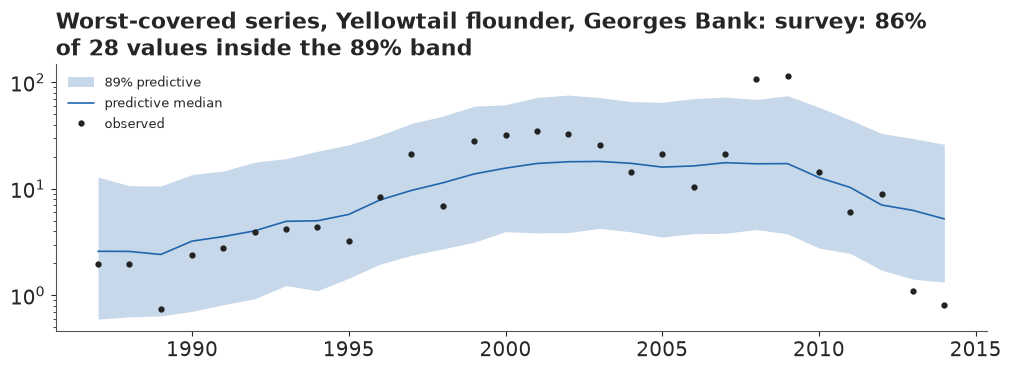

In [16]:
LP_M, LQ_M, SO_M = draws(id_main, "logP"), draws(id_main, "log_qK"), draws(id_main, "sigma_o")
ppc_rng = np.random.default_rng(5)
sub = ppc_rng.choice(LP_M.shape[0], 1000, replace=False)
os_, oi_ = D["obs_ser"], D["obs_state"]
REP = (LQ_M[sub][:, os_] + LP_M[sub][:, oi_]
       + SO_M[sub][:, os_] * ppc_rng.normal(size=(len(sub), len(os_))))
lo_m, hi_m = np.quantile(REP, [0.055, 0.945], axis=0)
inside_m = (D["logI"] >= lo_m) & (D["logI"] <= hi_m)
PPC = pd.DataFrame({"series": [f"{NICE[n.split(':')[0]]}: {n.split(':')[1]}"
                               for n in D["ser_name"]],
                    "values": np.bincount(os_),
                    "inside_89": np.bincount(os_, inside_m) / np.bincount(os_),
                    "sigma_o": np.median(SO_M, 0)}).set_index("series").sort_values("inside_89")
print(PPC.round(2).to_string())
print(f"\nall series: {inside_m.mean():.0%} of {len(inside_m)} values inside their 89% band; "
      f"series below 80%: {int((PPC.inside_89 < 0.8).sum())}")
worst = int(np.argmin(np.bincount(os_, inside_m) / np.bincount(os_)))
w_sel = os_ == worst
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(D["years"][oi_[w_sel]], np.exp(lo_m[w_sel]), np.exp(hi_m[w_sel]), color=HI,
                alpha=0.25, lw=0, label="89% predictive")
ax.plot(D["years"][oi_[w_sel]], np.exp(np.median(REP[:, w_sel], 0)), color=HI, lw=1.2,
        label="predictive median")
ax.plot(D["years"][oi_[w_sel]], np.exp(D["logI"][w_sel]), "o", color=INK, ms=3.5, label="observed")
ax.set_yscale("log")
ax.legend(fontsize=9.5)
ax.set_title(wrap(f"Worst-covered series, {PPC.index[0]}: {PPC.inside_89.iloc[0]:.0%} of "
                  f"{PPC['values'].iloc[0]} values inside the 89% band", 70), loc="left");
del LP_M, REP

Of the 728 index values, 98% fall inside their 89% bands, more than the nominal 89% because the
states are free to follow each index, the same leniency as for Pacific cod. No series falls below
80%. The worst, Georges Bank yellowtail's survey (86%), has the largest observation sd (about
0.8). Two isolated spikes, 107 and 115 kg per tow in 2008-09 against 21 in 2007 and 15 in 2010,
sit above the band; they look like outliers, and they inflate that sd. The last two values,
2013-14, about a hundredth of the spikes, sit well below it: so noisy a survey lets the model
treat the final collapse partly as noise. Part E tests both. The check cannot say whether the
dynamics are right; the official assessments test that below.

### How much did the data teach us about growth?

For each stock we compare the prior and posterior of $\log r$. The prior here is the hierarchical
one, simulated in NumPy from the same half-normal scales. The **contraction** is $1 -
\mathrm{var}_{post}/\mathrm{var}_{prior}$: 0 means the data taught nothing, 1 that they settled
it.

In [17]:
DRAW = {v: draws(id_main, v) for v in ("r", "log_K")}
BB, UU = status(id_main, D)
pr_rng = np.random.default_rng(11)
n_pr = 20000
sf_pr, tr_pr = np.abs(pr_rng.normal(0, 0.4, n_pr)), np.abs(pr_rng.normal(0, 0.4, n_pr))
LOGR_PRIOR = {}
rows = []
for s, sid in enumerate(MAIN):
    single = D["fam_names"][D["fam"][s]] == "(single)"
    pl = (D["m_r"][s] + (0 if single else sf_pr * pr_rng.normal(size=n_pr))
          + tr_pr * pr_rng.normal(size=n_pr))
    LOGR_PRIOR[sid] = pl
    po = np.log(DRAW["r"][:, s])
    msy = np.exp(po + DRAW["log_K"][:, s]) / 4 * D["cmax"][s]
    rows.append(dict(stock=NICE[sid], resilience=RAM.loc[RAM.stockid == sid, "resilience"].iloc[0],
                     cmsy_range=f"{np.exp(D['m_r'][s] - 2 * D['s_r'][s]):.2g}-"
                                f"{np.exp(D['m_r'][s] + 2 * D['s_r'][s]):.2g}",
                     r_prior=np.exp(np.median(pl)),
                     prior_95=f"{np.exp(np.quantile(pl, 0.025)):.2f}-"
                              f"{np.exp(np.quantile(pl, 0.975)):.2f}",
                     r_post=np.exp(np.median(po)),
                     r_post_89=f"{np.exp(np.quantile(po, 0.055)):.2f}-"
                               f"{np.exp(np.quantile(po, 0.945)):.2f}",
                     contraction=1 - po.var() / pl.var(),
                     MSY_t=f"{np.median(msy):,.0f} ({np.quantile(msy, 0.055):,.0f}-"
                           f"{np.quantile(msy, 0.945):,.0f})"))
RTAB = pd.DataFrame(rows).set_index("stock")
print(RTAB.round(2).to_string())
print(f"contraction: median {RTAB.contraction.median():.0%}, range {RTAB.contraction.min():.0%} "
      f"to {RTAB.contraction.max():.0%}")

                                             resilience cmsy_range  r_prior   prior_95  r_post  r_post_89  contraction                     MSY_t
stock                                                                                                                                           
Pacific cod, Hecate Strait                          Low   0.05-0.5     0.16  0.05-0.53    0.14  0.06-0.23         0.46       2,735 (1,271-5,732)
Pacific cod, W. Vancouver Island                    Low   0.05-0.5     0.16  0.05-0.55    0.13  0.06-0.23         0.43         1,089 (513-2,072)
Pacific cod, Queen Charlotte Sound                  Low   0.05-0.5     0.16  0.05-0.51    0.13  0.06-0.22         0.47           979 (429-2,492)
Rock sole, Queen Charlotte Sound                    Low   0.05-0.5     0.16  0.05-0.51    0.17  0.09-0.31         0.51           623 (319-1,512)
Rock sole, Hecate Strait                            Low   0.05-0.5     0.16  0.05-0.51    0.16  0.09-0.27         0.58         1,2

In the hierarchy the CMSY range sets only the centre of each stock's prior; the spread comes from
the two half-normal scales, so the prior 95% ranges are narrower than CMSY's for stocks alone in
their family, wider for the hakes, and much narrower for redfish (0.04-0.21 against 0.015-0.5).
The redfish's small contraction therefore means the data added little to a range the hierarchy
had already narrowed.

For most stocks the data narrowed $r$ by a third to a half (median about 45%) and left its centre
close to the prior's; for trevally, ling and blue shark, each alone in its family, by about 15%
or less. The hakes show the family effect working: their "medium" prior is centred at 0.4, the
four stocks together say about 0.2, and the family effect carries that lesson to all four. So the
growth rate is largely prior, adjusted a little by the data, the state of knowledge for one-way
trips. MSY's 89% ranges span factors of about three to nine.

### A check against the official assessments

Fourteen of the eighteen stocks have an official B/B<sub>MSY</sub> series in RAM. For each, we
compare the shape of the two histories (the correlation of the log posterior median with the log
official value, across years), the share of years in which the official value lies inside our
89% interval, and whether the two agree on the status in the official series' last year (our
P(B < B<sub>MSY</sub>) above or below one half, against the official value below or above 1).

In [18]:
rows = []
for s, sid in enumerate(MAIN):
    sel = D["st"] == s
    g = stock_rows(sid)
    off = g.bdivbmsy.to_numpy()
    ok = ~np.isnan(off)
    if ok.sum() < 6:
        continue
    b = BB[:, sel]
    med = np.median(b, 0)
    lo_, hi_ = np.quantile(b[:, ok], [0.055, 0.945], axis=0)
    j = np.where(ok)[0][-1]
    p_below = (b[:, j] < 1).mean()
    rows.append(dict(stock=NICE[sid], years=int(ok.sum()), last=int(g.year[j]),
                     corr_log=np.corrcoef(np.log(med[ok]), np.log(off[ok]))[0, 1],
                     inside_89=((off[ok] >= lo_) & (off[ok] <= hi_)).mean(),
                     ours_median=np.median(b[:, j]), P_below=p_below,
                     P_half=(b[:, j] < 0.5).mean(), official=off[j],
                     agree=(p_below > 0.5) == (off[j] < 1)))
AGREE = pd.DataFrame(rows).set_index("stock").sort_values("corr_log", ascending=False)
print(AGREE.round(2).assign(corr_log=AGREE.corr_log.round(3)).to_string())
print(f"\n{len(AGREE)} stocks: median correlation {AGREE.corr_log.median():.2f}; "
      f"{int((AGREE.corr_log >= 0.8).sum())} at 0.8 or above; status agrees for "
      f"{int(AGREE.agree.sum())} of {len(AGREE)}; official inside our 89% band in "
      f"{AGREE.inside_89.mean():.0%} of stock-years on average")
OFF_LOW, OURS_LOW = AGREE.official < 1, AGREE.P_below > 0.5
print(pd.crosstab(OURS_LOW.rename("ours: P(B<Bmsy) > 0.5"),
                  OFF_LOW.rename("official B/Bmsy < 1")).to_string())
N_OPT, N_PES = int((OFF_LOW & ~OURS_LOW).sum()), int((~OFF_LOW & OURS_LOW).sum())
print(f"officially below B_MSY: {int(OFF_LOW.sum())}, of which we call "
      f"{int((OFF_LOW & OURS_LOW).sum())}; "
      f"disagreements: {N_OPT} with our model more optimistic, {N_PES} more pessimistic")
OVERF = AGREE[AGREE.official < 0.5]
print(f"officially overfished (below half B_MSY) in their last assessed year: {len(OVERF)}; "
      f"ours P(B < Bmsy/2) there: "
      + ", ".join(f"{nm} {int(r['last'])} {r['P_half']:.2f}" for nm, r in OVERF.iterrows()))

                                     years  last  corr_log  inside_89  ours_median  P_below  P_half  official  agree
stock                                                                                                               
Silver hake, Scotian Shelf              22  2014     0.967       1.00         2.27     0.01    0.00      2.47   True
Pacific cod, W. Vancouver Island        46  2001     0.943       0.87         0.41     0.99    0.70      0.67   True
Snapper, New Zealand (SNA 7)            83  2013     0.890       0.64         2.80     0.06    0.00      0.66  False
Rock sole, Hecate Strait                61  2005     0.882       0.07         0.98     0.52    0.04      2.58  False
Yellowtail flounder, Grand Banks        50  2014     0.881       0.78         2.40     0.00    0.00      1.76   True
Pacific cod, Hecate Strait              57  2012     0.875       0.89         0.82     0.68    0.15      0.66   True
Redfish, Grand Banks                    55  2013     0.812      

For half of the stocks the shape of the history agrees well (correlation 0.8 or more; trevally
falls just short): they rise and fall when the official assessment says they did. The levels agree
less often: the official value lies inside our 89% band in about two thirds of the years, and the
last-year status agrees for 8 of the 14 stocks. The misses are not random. Of the 7 stocks the
official assessments put below B<sub>MSY</sub>, our model calls only 2, and 5 of the 6
disagreements are our model being the more optimistic.

The sharpest test is the title's own question. Three stocks are officially *overfished*, below
half of B<sub>MSY</sub>, in their last assessed year: witch flounder (0.19 in 2011), Georges Bank
yellowtail (0.22 in 2007) and Chilean hake (0.47 in 2015). Our model calls none of them
overfished, giving each at most a few percent chance of it; it puts witch flounder at 1.4 times
B<sub>MSY</sub>, seven times the official level. New Zealand snapper, officially at 0.13-0.2 of
B<sub>MSY</sub> from the mid-1980s to 2009 and 0.66 in 2013, comes out at 2.8.

Some of the gap is definitional (many assessments measure spawning biomass, or take
B<sub>MSY</sub> from an age-structured model), and some is the model: a prior that leans healthy
(part C), and catch rates that can hold up while the fish decline. Hecate Strait rock sole, the
one miss the other way, shows both concretely. Its official series starts at about four times
B<sub>MSY</sub>, which a Schaefer stock cannot reach (unfished is twice B<sub>MSY</sub>). And its
catch rate, the series our model follows most closely, fell about tenfold from the late 1950s to
the mid-1980s while the official series fell about twofold (part A's correlation of -0.17).

Two stocks disagree outright in shape (correlation below 0.4), with blue shark and Queen Charlotte
Sound rock sole weak too. Chilean hake's assessment has a crash after 2000 that our catch-rate
index does not show; Georges Bank yellowtail comes out healthy in 2007. Witch flounder, snapper,
rock sole, Chilean hake and Georges Bank yellowtail are the stocks to quote with care.

## E · Below the healthy level, and still being fished hard?

### Kobe probabilities

Each stock's last year of data is its "now": between 2001 (Pacific cod off western Vancouver
Island) and 2015 (Chilean hake), since RAM v4.44 holds assessments up to about 2016. For each
draw we have a point on the Kobe plot, so each quadrant has a probability.

In [19]:
LAST = D["last"]
B_LAST, U_LAST = BB[:, LAST], UU[:, LAST]
KOBE = pd.DataFrame({
    "year": D["years"][LAST],
    "P(B<Bmsy)": (B_LAST < 1).mean(0), "P(B<Bmsy/2)": (B_LAST < 0.5).mean(0),
    "P(F>Fmsy)": (U_LAST > 1).mean(0),
    "healthy": ((B_LAST >= 1) & (U_LAST <= 1)).mean(0),
    "recovering": ((B_LAST < 1) & (U_LAST <= 1)).mean(0),
    "overfishing": ((B_LAST >= 1) & (U_LAST > 1)).mean(0),
    "both": ((B_LAST < 1) & (U_LAST > 1)).mean(0),
    "B/Bmsy": np.median(B_LAST, 0), "F/Fmsy": np.median(U_LAST, 0)},
    index=[NICE[s] for s in MAIN]).sort_values("P(B<Bmsy)", ascending=False)
print(KOBE.round(2).to_string())
N_BELOW = (B_LAST < 1).sum(axis=1)  # stocks below B_MSY, per draw
N_F = (U_LAST > 1).sum(axis=1)
CNT = pd.Series(N_BELOW).value_counts(normalize=True).sort_index()
print("\nnumber of the 18 stocks below B_MSY in their last year, posterior:",
      {int(k): round(float(v), 3) for k, v in CNT.items()})
print(f"median {np.median(N_BELOW):.0f}, 89% {np.quantile(N_BELOW, 0.055):.0f}-"
      f"{np.quantile(N_BELOW, 0.945):.0f}; stocks with P(B<Bmsy) > 0.5: "
      f"{int((KOBE['P(B<Bmsy)'] > 0.5).sum())}; sum of probabilities "
      f"{KOBE['P(B<Bmsy)'].sum():.1f}")
print(f"stocks fished above F_MSY: median {np.median(N_F):.0f}, 89% "
      f"{np.quantile(N_F, 0.055):.0f}-{np.quantile(N_F, 0.945):.0f}; "
      f"with P(F>Fmsy) > 0.5: {int((KOBE['P(F>Fmsy)'] > 0.5).sum())}")

                                           year  P(B<Bmsy)  P(B<Bmsy/2)  P(F>Fmsy)  healthy  recovering  overfishing  both  B/Bmsy  F/Fmsy
Pacific cod, W. Vancouver Island           2001       0.99         0.70       0.32     0.01        0.67         0.00  0.32    0.41    0.79
Pacific cod, Hecate Strait                 2012       0.68         0.15       0.03     0.32        0.65         0.00  0.03    0.82    0.33
Yellowtail flounder, Georges Bank          2014       0.60         0.15       0.00     0.40        0.60         0.00  0.00    0.88    0.02
Rock sole, Hecate Strait                   2005       0.52         0.04       0.04     0.47        0.49         0.01  0.03    0.98    0.53
Pacific cod, Queen Charlotte Sound         2012       0.50         0.05       0.01     0.50        0.49         0.00  0.01    1.00    0.19
Silver hake, S. Georges Bank-Mid-Atlantic  2013       0.46         0.11       0.00     0.54        0.46         0.00  0.00    1.06    0.03
Ling, SE Australia         

The probabilities sort the stocks cleanly at the ends and leave a crowd in the middle. Pacific cod
off western Vancouver Island in 2001 is almost certainly below B<sub>MSY</sub>, with about a 70%
chance of being below half of it; Grand Banks yellowtail and Scotian Shelf silver hake are almost
certainly above. Five stocks have P(B < B<sub>MSY</sub>) between about 0.45 and 0.6: the data
cannot place them. Only four stocks are more likely than not below it, and the fourth, Hecate
Strait rock sole at 0.52, barely.

Yet the expected number below the line is about 6, the sum of the 18 probabilities: many middling
probabilities add up. Counting, draw by draw, how many of the 18 are below B<sub>MSY</sub> gives
a median of 6 and an 89% range of 3 to 9: "about 6, and we cannot say exactly which". Four stocks
are each more likely than not below the line, but only one of them clearly; the 94% in the
how-sure sentence is for the count, at least 4 of the 18, whichever they are. Part D's check gives
the caveat a direction: if anything these counts are low.

The fishing pressure tells a calmer story: catches had fallen, and almost every stock was fished
below $F_{MSY}$ in its last year. Ling off south-east Australia is the one stock more likely than
not (54%) to be fished too hard. Most stocks below B<sub>MSY</sub> are "recovering": depleted,
but no longer being drained.

In [20]:
SURE_P = float((N_BELOW >= 4).mean())
SURE = pub.how_sure(
    SURE_P, "at least 4 of the 18 were below the healthy level then", "low",
    "the model is simpler than the official assessments and, where they disagree, usually the "
    "more optimistic, so if anything it undercounts")
print(SURE)
HOW_SURE.update(Markdown("**How sure are we.** " + SURE))

It is *very likely* (94%) that at least 4 of the 18 were below the healthy level then. We have *low confidence* in that figure: the model is simpler than the official assessments and, where they disagree, usually the more optimistic, so if anything it undercounts.


### The noise that decides one stock

Georges Bank yellowtail is the stock to worry about. The official assessment in RAM ends in 2007
at about a fifth of B<sub>MSY</sub>; our shared-noise model puts it a little below the line in
2014, with a wide range. Fitted alone, its answer hangs on the process noise, which part C showed
it cannot learn by itself. Refitting it with the noise fixed at three values shows how much, and a
last refit at the shared value drops the two survey spikes of 2008-09:

In [21]:
sel_g = D["st"] == MAIN.index("YELLGB")
bb_g = BB[:, sel_g]
i07 = int(np.where(DG["years"] == 2007)[0][0])


def yg_row(label, sd, bb, div):
    return dict(process_sd=label, sd=sd, B_Bmsy_2007=np.median(bb[:, i07]),
                B_Bmsy_2014=np.median(bb[:, -1]), P_below=(bb[:, -1] < 1).mean(),
                P_half=(bb[:, -1] < 0.5).mean(), divergences=div)


spike = np.isin(DG["years"][DG["obs_state"]], [2008, 2009])  # the two survey spikes
DG_NS = dict(DG, obs_state=DG["obs_state"][~spike], obs_ser=DG["obs_ser"][~spike],
             logI=DG["logI"][~spike])
rows = [yg_row("shared (18 stocks)", f"{np.median(SP):.2f}", bb_g, DIV_MAIN)]
t0 = time.time()
ALONE = "fixed, yellowtail alone"
for sp_fix, dd, label in ((0.1, DG, ALONE), (0.24, DG, ALONE), (0.4, DG, ALONE),
                          (0.24, DG_NS, "fixed, without 2008-09 survey")):
    idf, _ = sample(ss_model(dd, sigma_p=sp_fix), dd, RANDOM_SEED, ta=0.95)
    bbf, _ = status(idf, dd)
    rows.append(yg_row(label, f"{sp_fix:.2f}", bbf, int(idf.sample_stats["diverging"].sum())))
    if dd is DG_NS:
        print(f"without the spikes: survey sigma_o median {np.median(draws(idf, 'sigma_o')):.2f}")
    del idf
TIMES["yellowtail sensitivity"] = time.time() - t0
YG = pd.DataFrame(rows)
print(YG.round(2).to_string(index=False))
gy = stock_rows("YELLGB").dropna(subset=["bdivbmsy"])
print(f"official B/Bmsy: last value {gy.bdivbmsy.iloc[-1]:.2f} in {gy.year.iloc[-1]}")

without the spikes: survey sigma_o median 0.58
                   process_sd   sd  B_Bmsy_2007  B_Bmsy_2014  P_below  P_half  divergences
           shared (18 stocks) 0.24         2.69         0.88     0.60    0.15           11
      fixed, yellowtail alone 0.10         1.84         1.73     0.02    0.00            0
      fixed, yellowtail alone 0.24         2.71         0.85     0.63    0.16            0
      fixed, yellowtail alone 0.40         3.37         0.24     0.99    0.87          147
fixed, without 2008-09 survey 0.24         2.34         0.55     0.88    0.43            0
official B/Bmsy: last value 0.22 in 2007


With a process sd of 0.1 the model must explain the survey's decline through the dynamics, which
the catches cannot do, and the stock comes out healthy in 2014 (about 1.7 times B<sub>MSY</sub>).
At 0.24, the shared value, it lands just below the line, as in the main fit. At 0.4 the states
follow the survey down to about a quarter of B<sub>MSY</sub>, though with about 150 divergences.
The status moves from clearly healthy to overfished on a number the data on this stock cannot pin
down; sharing the noise is defensible, but for this stock the answer rests on it.

The spikes matter too. Without them the survey's observation sd falls from about 0.8 to about
0.6, and 2014 moves to about 0.55 of B<sub>MSY</sub>, with about a 40% chance of being
overfished. The 2007 disagreement does not move: every fit puts 2007 above B<sub>MSY</sub>,
against an official 0.22, so that gap has another cause, most likely the half-century before the
survey, which the model fills with dynamics and a prior that starts the stock healthy.

## F · Catch only: what the prior alone says

### Northern cod

Hundreds of the world's fisheries have catch records but no index and no assessment. Methods such
as CMSY (Froese et al. 2017) estimate their status from catches plus priors. Northern cod gives a
hard test: 56 years of catch (1959-2014) and an official B/B<sub>MSY</sub> for 50 of them, but no
index in RAM. We fit the same model with no index, with northern cod's own "medium" resilience
prior for $r$, and then add the CMSY rule for the final depletion: when the last catch is below
half the largest, CMSY keeps only histories that end at 1-40% of $K$. CMSY applies it as a hard
filter; we impose it as a steep wall on the last state.

northern cod: 56 catch years, largest catch 810,000 t in 1968, last/largest = 0.006


catch + priors: 2 divergences; r median 0.43 (prior 0.40); B/Bmsy 1992 1.83 (official 0.05; P(below half) 0.00); 2014 1.98 (89% 1.59-2.39); 2011 1.98 (official 0.07); P(B < Bmsy/2 in 2014) 0.00; corr(log) with official -0.75


+ CMSY end filter (1-40% of K): 216 divergences; r median 0.34 (prior 0.40); B/Bmsy 1992 1.54 (official 0.05; P(below half) 0.05); 2014 0.71 (89% 0.41-0.91); 2011 1.15 (official 0.07); P(B < Bmsy/2 in 2014) 0.12; corr(log) with official -0.50


lower floor (0.2% of K): 2 divergences; B/Bmsy 1992 1.82 (89% 1.25-2.31); lowest B/Bmsy of any year, 5th percentile over draws 0.51
catch-only r: contraction 7% against its N(log 0.4, 0.35) prior


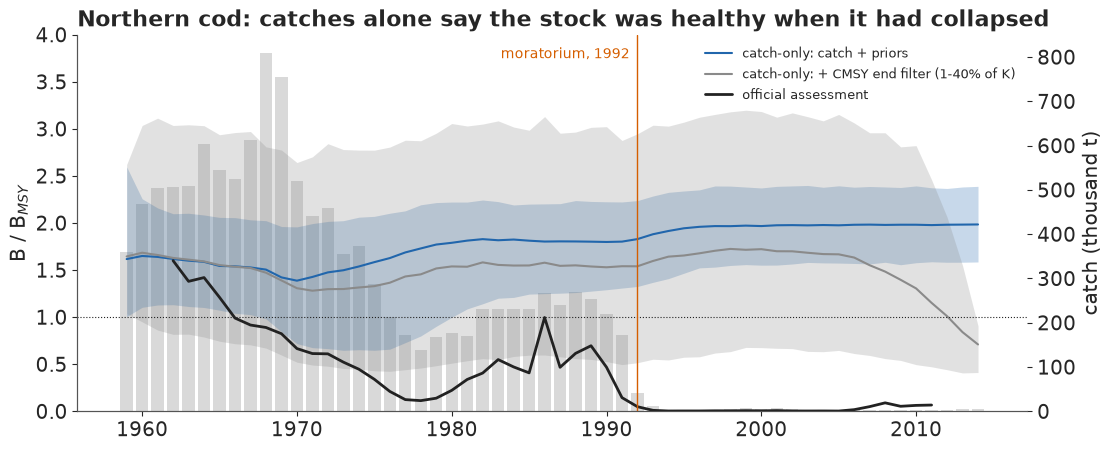

In [22]:
DC = prep(["COD2J3KL"], use_index=False, multi_only=False)
gc = stock_rows("COD2J3KL")
OFF_COD = gc.bdivbmsy.to_numpy()
j_off = int(np.where(~np.isnan(OFF_COD))[0][-1])  # the official series ends before the catches
ratio = gc.catch_t.iloc[-1] / gc.catch_t.max()
print(f"northern cod: {DC['N']} catch years, largest catch {gc.catch_t.max():,.0f} t in "
      f"{gc.year[gc.catch_t.idxmax()]}, last/largest = {ratio:.3f}")
i92 = int(np.where(DC["years"] == 1992)[0][0])
COD = {}
t0 = time.time()
for label, ep in (("catch + priors", None), ("+ CMSY end filter (1-40% of K)", (0.01, 0.4))):
    idc, _ = sample(ss_model(DC, eps=0.03, pen=0.02, end_prior=ep), DC, RANDOM_SEED)
    bbc, _ = status(idc, DC)
    COD[label] = bbc
    ok = ~np.isnan(OFF_COD)
    print(f"{label}: {int(idc.sample_stats['diverging'].sum())} divergences; r median "
          f"{np.median(draws(idc, 'r')):.2f} (prior {np.exp(DC['m_r'][0]):.2f}); B/Bmsy 1992 "
          f"{np.median(bbc[:, i92]):.2f} (official {OFF_COD[i92]:.2f}; P(below half) "
          f"{(bbc[:, i92] < 0.5).mean():.2f}); 2014 "
          f"{np.median(bbc[:, -1]):.2f} (89% {np.quantile(bbc[:, -1], 0.055):.2f}-"
          f"{np.quantile(bbc[:, -1], 0.945):.2f}); "
          f"{DC['years'][j_off]} {np.median(bbc[:, j_off]):.2f} "
          f"(official {OFF_COD[j_off]:.2f}); "
          f"P(B < Bmsy/2 in 2014) {(bbc[:, -1] < 0.5).mean():.2f}; corr(log) with official "
          f"{np.corrcoef(np.log(np.median(bbc, 0)[ok]), np.log(OFF_COD[ok]))[0, 1]:.2f}")
    if label == "catch + priors":
        R_COD = draws(idc, "r").ravel()
    del idc
# the smooth floor (eps) and the feasibility penalty set the lowest state the model can reach;
# refit with both ten times lower, so that a collapse to 0.1-0.5% of K is representable
idc, _ = sample(ss_model(DC, eps=0.002, pen=0.002, floor=0.002), DC, RANDOM_SEED)
bbc, _ = status(idc, DC)
print(f"lower floor (0.2% of K): {int(idc.sample_stats['diverging'].sum())} divergences; B/Bmsy "
      f"1992 {np.median(bbc[:, i92]):.2f} (89% {np.quantile(bbc[:, i92], 0.055):.2f}-"
      f"{np.quantile(bbc[:, i92], 0.945):.2f}); lowest B/Bmsy of any year, 5th percentile "
      f"over draws {np.quantile(bbc.min(axis=1), 0.05):.2f}")
del idc, bbc
CONTR_COD = 1 - np.log(R_COD).var() / DC["s_r"][0] ** 2
print(f"catch-only r: contraction {CONTR_COD:.0%} against its N(log 0.4, {DC['s_r'][0]:.2f}) prior")
TIMES["northern cod"] = time.time() - t0

fig, ax = plt.subplots(figsize=(11, 4.4))
axc = ax.twinx()
axc.bar(gc.year, gc.catch_t / 1e3, color=LIGHT, width=0.8, zorder=0)
axc.set_ylabel("catch (thousand t)")
axc.grid(False)
ax.set_zorder(axc.get_zorder() + 1)
ax.patch.set_visible(False)
for (label, bbc), c in zip(COD.items(), (HI, MUTED)):
    lo_, hi_ = np.quantile(bbc, [0.055, 0.945], axis=0)
    ax.fill_between(DC["years"], lo_, hi_, color=c, alpha=0.25, lw=0)
    ax.plot(DC["years"], np.median(bbc, 0), color=c, lw=1.5, label=f"catch-only: {label}")
ax.plot(gc.year, OFF_COD, color=INK, lw=2, label="official assessment")
ax.axhline(1, color=INK, lw=0.8, ls=":")
ax.axvline(1992, color=LO, lw=1)
ax.text(1991.5, 3.75, "moratorium, 1992", color=LO, fontsize=10, ha="right")
ax.set_ylim(0, 4.0)
ax.set_ylabel("B / B$_{MSY}$")
ax.legend(loc="upper right", fontsize=9.5)
ax.set_title("Northern cod: catches alone say the stock was healthy when it had collapsed",
             loc="left");

The catch-only posterior misses the collapse completely. In 1992, when the official assessment
puts northern cod at about 5% of B<sub>MSY</sub>, the catch-only model puts it near twice
B<sub>MSY</sub>, and its 2014 range does not reach below about 1.6. CMSY's end filter forces 2014
down to about 0.7, but that is the rule speaking, and it does not reach back to the collapse: 1992
stays at about 1.5, with about a 1-in-20 chance of being below half the healthy level. The wall
fights 22 years of near-zero catches during which the dynamics, with a growth rate of about 0.34,
regrow any stock; some 200 divergences show the strain. Both histories are negatively correlated
with the official one.

Could the model have shown the collapse at all? Its smooth floor and feasibility penalty (at 3%
and 2% of $K$) set the lowest state it can represent, about 0.04 of B<sub>MSY</sub>, above the
official 0.003-0.01 of 1993-2005. With both about ten times lower nothing changes: 1992 comes out
at about 1.8, and 95% of the draws never go below about 0.5 in any year. The miss is what catches
mean. A catch series that rises and falls fits a stock that was fished down (the catch fell
because there were no fish) and one that was lightly fished (the catch fell because of a
moratorium). Without an index the prior and dynamics choose: the prior paths that survive the
catches are big stocks (part C), and falling catches plus a positive growth rate mean recovery.
Free et al. (2020, *Fisheries Research*, "Blood from a stone") tested catch-only methods against
full assessments and gave their verdict in the title.

### The same blindness on stocks we know

The northern cod result could be a peculiarity of that stock. Refitting three data-rich stocks
from part D without their indices tests that:

In [23]:
rows = []
t0 = time.time()
for sid in ("PCODWCVANI", "YELL3LNO", "REDFISHSPP3LN"):
    dco = prep([sid], use_index=False, multi_only=False)
    idc, _ = sample(ss_model(dco, eps=0.03, pen=0.02), dco, RANDOM_SEED)
    bbc, _ = status(idc, dco)
    off = stock_rows(sid).bdivbmsy.to_numpy()
    ok = ~np.isnan(off)
    s = MAIN.index(sid)
    rows.append(dict(stock=NICE[sid], year=int(dco["years"][-1]),
                     catch_only=np.median(bbc[:, -1]), with_index=np.median(BB[:, D["last"][s]]),
                     official=off[ok][-1],
                     corr_catch_only=np.corrcoef(np.log(np.median(bbc, 0)[ok]),
                                                 np.log(off[ok]))[0, 1],
                     divergences=int(idc.sample_stats["diverging"].sum())))
    del idc
TIMES["catch-only refits"] = time.time() - t0
print(pd.DataFrame(rows).set_index("stock").round(2).to_string())

                                  year  catch_only  with_index  official  corr_catch_only  divergences
stock                                                                                                 
Pacific cod, W. Vancouver Island  2001        1.76        0.41      0.67            -0.17            5
Yellowtail flounder, Grand Banks  2014        1.70        2.40      1.76             0.86            1
Redfish, Grand Banks              2013        1.78        1.50      1.31             0.61            2


Without its index, every stock ends well above B<sub>MSY</sub>, at about 1.7 to 1.8 times it.
The last-year value is roughly the same whatever happened: catches fell at the end of every one
of these records, and the model reads falling catches as regrowth. For Grand Banks yellowtail,
which really did recover, the answer is right by luck. For Pacific cod off western Vancouver
Island, which was depleted in 2001, it is wrong in the direction that matters.

## G · Explaining it to everyone

### The statistician's plot

A stock assessment report shows each stock's B/B<sub>MSY</sub> as a posterior median with a
shaded interval. Here it is for the six stocks of the headline, chosen to cover the cod, sole and
hake of the question and both agreement and disagreement with the official assessments.

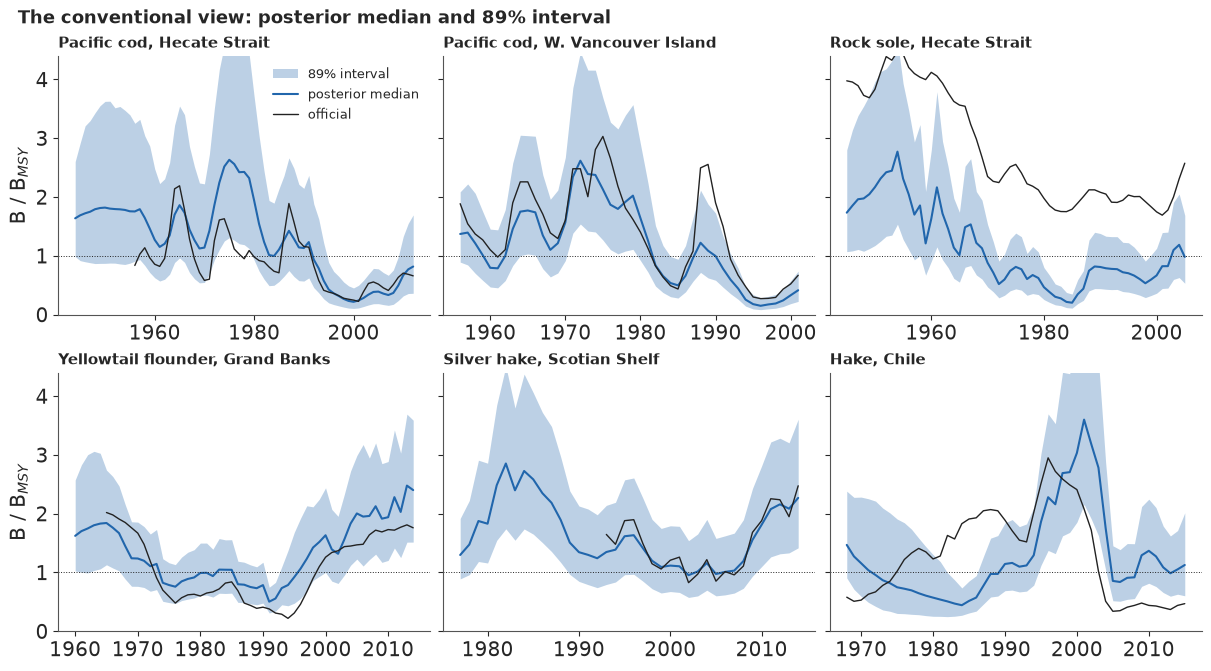

In [24]:
SHOW = ["PCODHS", "PCODWCVANI", "RSOLEHSTR", "YELL3LNO", "SHAKE4VWX", "SPHAKECH"]
fig, axs = plt.subplots(2, 3, figsize=(12, 6.6), sharey=True)
for a, sid in zip(axs.flat, SHOW):
    s = MAIN.index(sid)
    sel = D["st"] == s
    y, b = D["years"][sel], BB[:, sel]
    a.fill_between(y, *np.quantile(b, [0.055, 0.945], axis=0), color=HI, alpha=0.3, lw=0,
                   label="89% interval")
    a.plot(y, np.median(b, 0), color=HI, lw=1.5, label="posterior median")
    g = stock_rows(sid)
    a.plot(g.year, g.bdivbmsy, color=INK, lw=1, label="official")
    a.axhline(1, color=INK, lw=0.7, ls=":")
    a.set_ylim(0, 4.4)
    a.set_title(NICE[sid], loc="left", fontsize=11)
axs[0, 0].legend(fontsize=9, loc="upper right")
axs[0, 0].set_ylabel("B / B$_{MSY}$")
axs[1, 0].set_ylabel("B / B$_{MSY}$")
fig.suptitle("The conventional view: posterior median and 89% interval", x=0.01, ha="left",
             fontsize=13);

For a trained reader this is the right plot. For anyone else it has three problems. The band
reads as a physical object that "grows" where it widens, the error people make with the hurricane
"cone of uncertainty" (Ruginski et al. 2016, *Spatial Cognition & Computation*). The median looks
like what happened, although it is smoother than every real history. And the band's edges look
like limits.

### Forty possible histories

The public version draws 40 posterior paths instead, each a complete history the stock might have
had, thin and translucent so that where they crowd the eye sees confidence. Padilla, Ruginski &
Creem-Regehr (2017, *Cognitive Research*) found that ensembles avoid the cone's size misreading
but bring a bias of their own: readers over-weight wherever a single line falls. So we use 40
lines at low opacity, highlight none, add no median (Kale, Kay & Hullman 2021, *IEEE TVCG*, found
that a mean mark pulls readers away from the uncertainty), and say on the figure that each line
is one possible history. Each title is a count from the 40 paths, the catches sit underneath as
grey bars, and the years with an index are shaded: that is where the model "sees" the fish.

Pacific cod, Hecate Strait 40 of 40 histories fall below half the healthy level in the 2000s | last year 25 of 40 below 1, full posterior 0.68 | lines above 4.4: 10 of 40
Pacific cod, W. Vancouver I. 40 of 40 histories fall below half the healthy level in the 1990s | last year 40 of 40 below 1, full posterior 0.99 | lines above 4.4: 2 of 40
Rock sole, Hecate Strait 40 of 40 histories fall below half the healthy level in the 1980s | last year 14 of 40 below 1, full posterior 0.52 | lines above 4.4: 11 of 40
Yellowtail flounder, Grand Banks 19 of 40 histories fall below half the healthy level in the 1990s | last year 0 of 40 below 1, full posterior 0.00 | lines above 4.4: 1 of 40
Silver hake, Scotian Shelf only 1 of 40 histories ever fall below half the healthy level | last year 0 of 40 below 1, full posterior 0.01 | lines above 4.4: 4 of 40
Hake, Chile 30 of 40 histories fall below half the healthy level in the 1980s | last year 15 of 40 below 1, full posterior 0.38 | lines above 4.4: 1

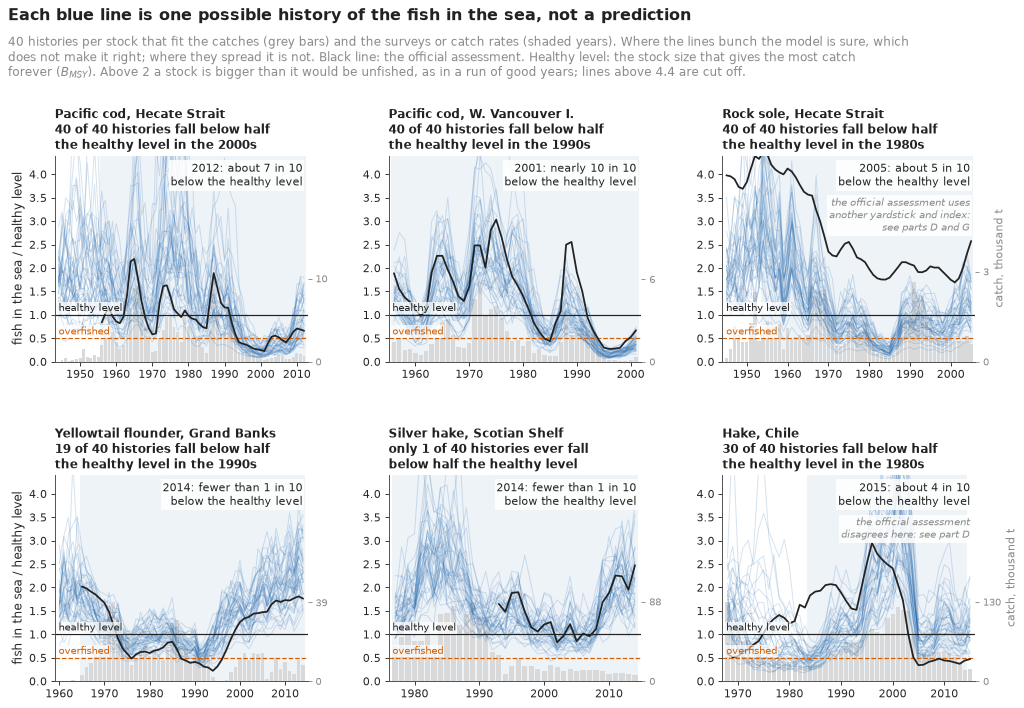

In [25]:
PICK = np.random.default_rng(114).choice(BB.shape[0], 40, replace=False)
SHORT = {"PCODHS": "Pacific cod, Hecate Strait", "PCODWCVANI": "Pacific cod, W. Vancouver I.",
         "RSOLEHSTR": "Rock sole, Hecate Strait", "YELL3LNO": "Yellowtail flounder, Grand Banks",
         "SHAKE4VWX": "Silver hake, Scotian Shelf", "SPHAKECH": "Hake, Chile"}


def panel_title(sid, paths, y):
    """A sentence from the 40 paths: the decade in which most fall below half of B_MSY."""
    dec = (y // 10) * 10
    counts = {int(D_): int((paths[:, dec == D_] < 0.5).any(axis=1).sum()) for D_ in np.unique(dec)}
    best = max(counts, key=counts.get)
    if counts[best] >= 10:
        return (f"{SHORT[sid]}\n{counts[best]} of 40 histories fall below half\n"
                f"the healthy level in the {best}s")
    n_any = int((paths < 0.5).any(axis=1).sum())
    return f"{SHORT[sid]}\nonly {n_any} of 40 histories ever fall\nbelow half the healthy level"


DISAGREE = {"RSOLEHSTR": "the official assessment uses\nanother yardstick and index:\n"
                         "see parts D and G",
            "SPHAKECH": "the official assessment\ndisagrees here: see part D"}


def headline_figure():
    fig, axs = plt.subplots(2, 3, figsize=(13, 9.0), layout="none", dpi=80)  # ~40% lighter
    fig.subplots_adjust(left=0.055, right=0.94, top=0.78, bottom=0.05, wspace=0.32, hspace=0.55)
    for j, (a, sid) in enumerate(zip(axs.flat, SHOW)):
        s = MAIN.index(sid)
        sel = D["st"] == s
        y, paths = D["years"][sel], BB[PICK][:, sel]
        g = stock_rows(sid)
        ac = a.twinx()
        ac.bar(g.year, g.catch_t / 1e3, color=LIGHT, width=0.8, zorder=0)
        ac.set_ylim(0, g.catch_t.max() / 1e3 * 2.6)  # top tick well clear of the 0.5 and 1 lines
        ac.set_yticks([0, round(g.catch_t.max() / 1e3)])
        ac.tick_params(labelsize=9, colors=MUTED)
        ac.grid(False)
        if j % 3 == 2:
            ac.set_ylabel("catch, thousand t", fontsize=9.5, color=MUTED, labelpad=4)
        iy = g.year[g.cpue.notna() | g.survey.notna()]
        ac.axvspan(iy.min() - 0.5, iy.max() + 0.5, color="#eef3f8", zorder=-2, lw=0)
        a.set_zorder(ac.get_zorder() + 1)
        a.patch.set_visible(False)
        for p in paths:
            a.plot(y, p, color=HI, alpha=0.18, lw=0.9)
        a.axhline(1, color=INK, lw=1.1)
        a.axhline(0.5, color=LO, lw=1.1, ls="--")
        ok = g.bdivbmsy.notna()
        a.plot(g.year[ok], g.bdivbmsy[ok], color=INK, lw=1.6)
        a.set_ylim(0, 4.4)
        a.set_xlim(y[0] - 1, y[-1] + 1)
        a.tick_params(labelsize=10)
        a.set_title(panel_title(sid, paths, y), loc="left", fontsize=11, color=INK)
        p_last = (BB[:, sel][:, -1] < 1).mean()  # the full posterior, not the 40 lines
        k10 = round(10 * p_last)
        k_txt = ("fewer than 1" if k10 == 0 else "nearly 10" if k10 == 10 else f"about {k10}")
        a.text(0.98, 0.97, f"{y[-1]}: {k_txt} in 10\nbelow the healthy level",
               transform=a.transAxes, ha="right", va="top", fontsize=9.5, color=INK,
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
        if sid in DISAGREE:
            a.text(0.98, 0.80, DISAGREE[sid], transform=a.transAxes, ha="right", va="top",
                   fontsize=9, color=MUTED, style="italic",
                   bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
        if j % 3 == 0:
            a.set_ylabel("fish in the sea / healthy level", fontsize=10.5)
        for yv, txt, c in ((1.0, "healthy level", INK), (0.5, "overfished", LO)):
            a.text(0.015, yv + 0.03, txt, transform=a.get_yaxis_transform(), fontsize=9, color=c,
                   va="bottom", bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.8))
    fig.text(0.01, 0.985, "Each blue line is one possible history of the fish in the sea, not a "
             "prediction", fontsize=14.5, weight="bold", color=INK, va="top")
    fig.text(0.01, 0.948, wrap("40 histories per stock that fit the catches (grey bars) and the "
                               "surveys or catch rates (shaded years). Where the lines bunch "
                               "the model is sure, which does not make it right; where they "
                               "spread it is not. Black line: the official assessment. Healthy "
                               "level: the stock size that gives the most catch forever "
                               "($B_{MSY}$). Above 2 a stock is bigger than it would be "
                               "unfished, as in a run of good years; lines above 4.4 are cut "
                               "off.", 150),
             fontsize=11, color=MUTED, va="top")
    return fig


fig_top = headline_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
headline_figure()
for sid in SHOW:
    sel = D["st"] == MAIN.index(sid)
    print(panel_title(sid, BB[PICK][:, sel], D["years"][sel]).replace("\n", " "),
          f"| last year {int((BB[PICK][:, sel][:, -1] < 1).sum())} of 40 below 1, full posterior "
          f"{(BB[:, sel][:, -1] < 1).mean():.2f} | lines above 4.4: "
          f"{(BB[PICK][:, sel] > 4.4).any(axis=1).sum()} of 40")

Pacific cod in both areas and Hecate Strait rock sole fall below half the healthy level in every
one of the 40 histories, the cod around 2000 and the sole in the 1980s. Grand Banks yellowtail
dips in nearly half of them in the 1990s; Scotian Shelf silver hake almost never does. Two panels
carry a note because the model and the official assessment disagree. For Hecate Strait rock sole
the official line sits at about four times B<sub>MSY</sub> before 1965 and between 1.7 and 2.6
since about 1970, for the two reasons of part D, so "40 of 40" is our model's verdict alone: a
tight bunch of lines says that the model is sure, not that it is right. For Chilean hake about
30 of 40 histories fall below half in the 1980s while the official line sits above it.

Where the record starts before the index (Hecate Strait cod and rock sole, Grand Banks
yellowtail, Chilean hake), the lines fan out before it and draw together under it, though a noisy
index still lets them spread. Values above 2 mean a stock bigger than it would be unfished, which
the process noise allows in a run of good years. Each panel's box gives the last-year chance from
the full posterior, rounded to tenths as in the fish rows; the 40 lines are a random sample.

### Fish rows: how often is each stock below the line?

The headline shows six stocks over time; "is it below the healthy level now?" needs all 18 at
once, and 18 overlapping Kobe clouds are unreadable. So each stock gets a row of ten fish, an
**icon array** (Galesic, Garcia-Retamero & Gigerenzer 2009, *Health Psychology*): in about how
many of ten plausible worlds was the stock below the healthy level in its last year? Solid
vermilion fish are below half of it ("overfished"), hatched ones below it but above half, blue
ones above. `public.py` draws people, not fish, so the fish glyph is a local helper.

official marks: {'Pacific cod, W. Vancouver Island': '†', 'Snapper, New Zealand (SNA 7)': '†', 'Pacific cod, Hecate Strait': '†', 'Ling, SE Australia': '†', 'Witch flounder, Gulf of St Lawrence': '††', 'Yellowtail flounder, Georges Bank': '††', 'Hake, Chile': '††'} | other years: ['Yellowtail flounder, Georges Bank, 2007']
rows with more than 5 of 10 below: 3; stocks with P(B<Bmsy) > 0.5: 4


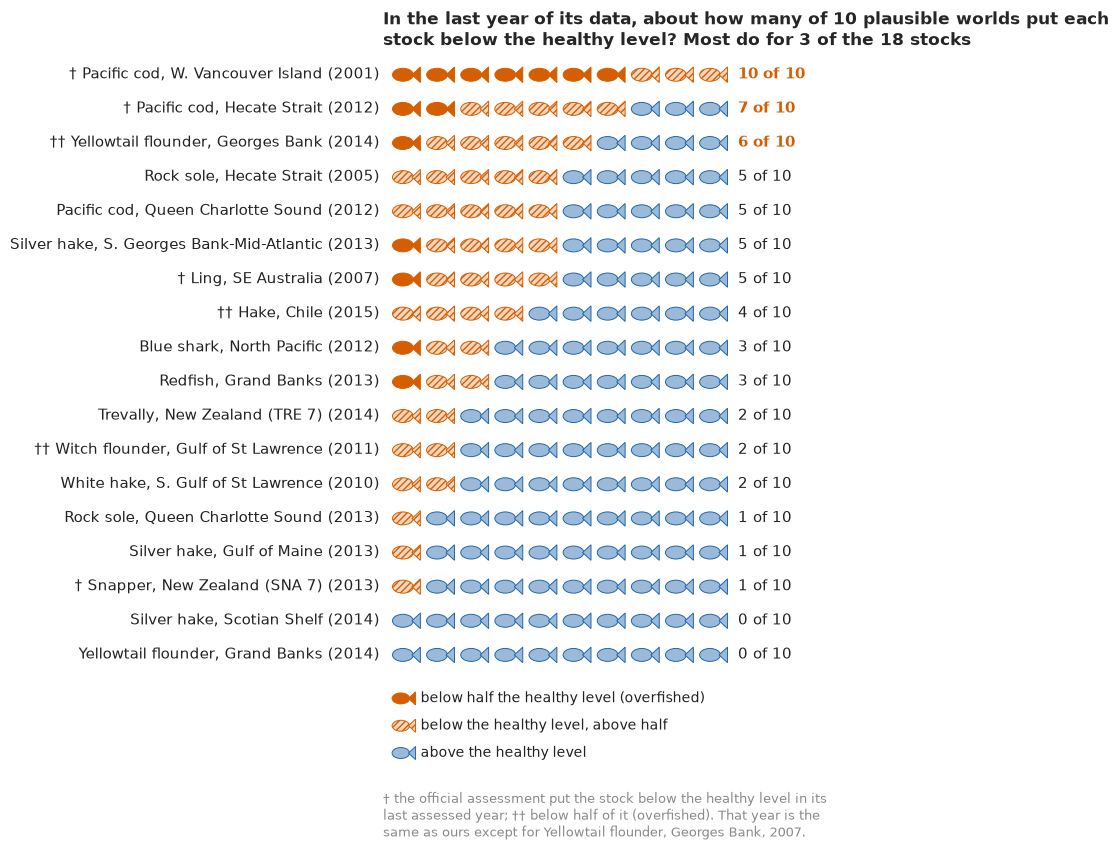

In [26]:
def fish(ax, x, y, s, fc, ec, hatch=None):  # local: the shared module draws people, not fish
    ax.add_patch(Ellipse((x + 0.4 * s, y + 0.5 * s), 0.64 * s, 0.4 * s, fc=fc, ec=ec, hatch=hatch,
                         lw=0.7))
    ax.add_patch(Polygon([(x + 0.68 * s, y + 0.5 * s), (x + 0.94 * s, y + 0.74 * s),
                          (x + 0.94 * s, y + 0.26 * s)], closed=True, fc=fc, ec=ec, hatch=hatch,
                         lw=0.7))


def fish_rows(ax, names, p_half, p_below, n=10):
    """One row of n fish per stock: solid LO below half B_MSY, hatched below B_MSY, HI above."""
    for i, (nm, ph, pb) in enumerate(zip(names, p_half, p_below)):
        y = len(names) - 1 - i
        k_half, k_below = int(round(n * ph)), int(round(n * pb))
        for j in range(n):
            if j < k_half:
                fish(ax, j, y, 0.95, LO, LO)
            elif j < k_below:
                fish(ax, j, y, 0.95, pub._shade(LO, "white", 0.75), LO, "/////")
            else:
                fish(ax, j, y, 0.95, pub._shade(HI, "white", 0.55), HI)
        ax.text(-0.3, y + 0.48, nm, ha="right", va="center", fontsize=10.5, color=INK)
        ax.text(n + 0.2, y + 0.48, f"{k_below} of {n}", ha="left", va="center", fontsize=10.5,
                color=LO if k_below > n / 2 else INK, weight="bold" if k_below > n / 2 else None)
    ax.set_xlim(-0.2, n + 1.4)
    ax.set_ylim(-3.9, len(names) + 0.1)
    ax.set_aspect("equal")
    ax.axis("off")
    for y0, fc, ec, h, txt in ((-1.2, LO, LO, None, "below half the healthy level (overfished)"),
                               (-2.0, pub._shade(LO, "white", 0.75), LO, "/////",
                                "below the healthy level, above half"),
                               (-2.8, pub._shade(HI, "white", 0.55), HI, None,
                                "above the healthy level")):
        fish(ax, 0, y0, 0.8, fc, ec, h)
        ax.text(0.9, y0 + 0.4, txt, fontsize=10, va="center", color=INK)


order = KOBE.index
fig, ax = plt.subplots(figsize=(10, 8.4))
DAG = {nm: ("\u2020\u2020" if v < 0.5 else "\u2020") for nm, v in AGREE.official.items() if v < 1}
fish_rows(ax, [f"{DAG.get(nm, '')} {nm} ({int(KOBE.loc[nm, 'year'])})".strip() for nm in order],
          KOBE.loc[order, "P(B<Bmsy/2)"], KOBE.loc[order, "P(B<Bmsy)"])
other_year = [f"{nm}, {int(AGREE.loc[nm, 'last'])}" for nm in DAG
              if AGREE.loc[nm, "last"] != KOBE.loc[nm, "year"]]
ax.text(-0.2, -3.5, wrap("\u2020 the official assessment put the stock below the healthy level in "
                         "its last assessed year; \u2020\u2020 below half of it (overfished). "
                         "That year is the same as ours except for " + "; ".join(other_year) + ".",
                         72),
        fontsize=9.5, color=MUTED, va="top", ha="left")
print("official marks:", DAG, "| other years:", other_year)
n_rows = int((np.round(10 * KOBE["P(B<Bmsy)"]) > 5).sum())  # the rows drawn, not the raw P
ax.set_title(wrap(f"In the last year of its data, about how many of 10 plausible worlds put each "
                  f"stock below the healthy level? Most do for {n_rows} of the 18 stocks", 80),
             loc="left", fontsize=12.5)
print(f"rows with more than 5 of 10 below: {n_rows}; stocks with P(B<Bmsy) > 0.5: "
      f"{int((KOBE['P(B<Bmsy)'] > 0.5).sum())}");

The rows read in a second: Pacific cod off western Vancouver Island at the top with ten of ten,
Hecate Strait cod and Georges Bank yellowtail at seven and six, a middle group at four or five
that the data cannot call, and a long tail almost certainly above the line. Rounding to tenths
costs something at the edge: rock sole (0.52) and Queen Charlotte Sound cod (0.50) both show five
of ten, so the rows show three stocks below the line in most worlds where part E counted four.
The daggers carry part D's warning onto the figure: witch flounder and snapper look healthy here
although their official assessments put them far below the line, and Georges Bank yellowtail is
officially overfished, with a survey that ended at a few percent of its 2000s level. Almost all
of these stocks were being fished lightly by their last year, which the rows do not show.

### Catch against what the stock can give

The savings account has a direct picture: the yearly catch against the withdrawal the account
can sustain. MSY is uncertain, so it is a **gradient band**, darker where more plausible, rather
than a line with error bars, which readers take as hard limits (Correll & Gleicher 2014, *IEEE
TVCG*). Catch bars above the band's middle are vermilion: eating the capital.

Pacific cod, Hecate Strait: MSY 2,735 t (89% 1,271-5,732, a factor of 4.5); catch above the median MSY in 25 of 69 years: 1957, 1958, 1959, 1963, 1964, 1965, 1966, 1967, 1968, 1972, 1973, 1974, 1975, 1976, 1977, 1979, 1980, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993
Yellowtail flounder, Grand Banks: MSY 17,701 t (89% 9,134-34,142, a factor of 3.7); catch above the median MSY in 9 of 55 years: 1970, 1971, 1972, 1973, 1974, 1975, 1979, 1985, 1986


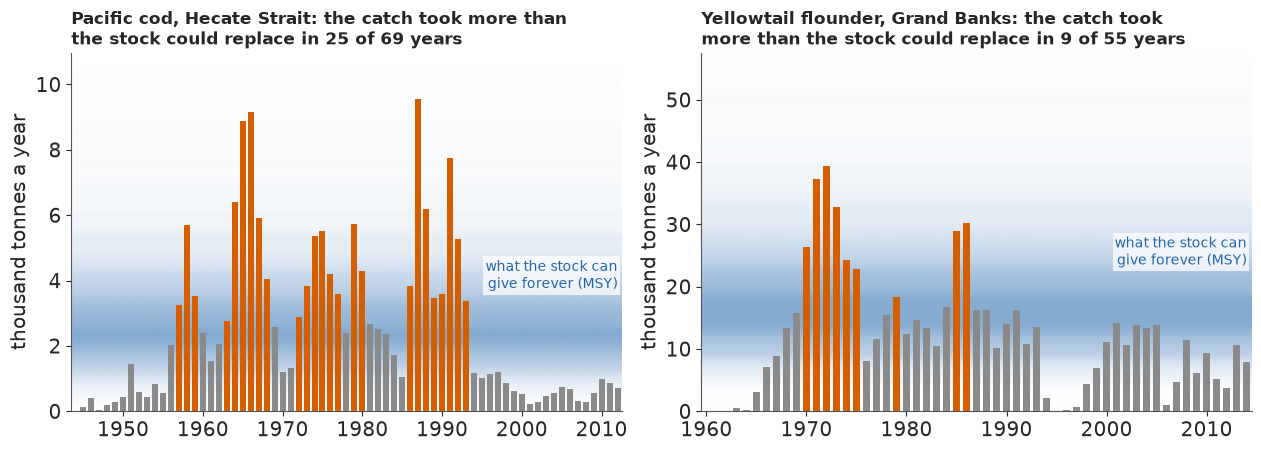

In [27]:
def msy_band(ax, sid):
    s = MAIN.index(sid)
    sel = D["st"] == s
    yrs = D["years"][sel]
    catch = D["C"][sel] * D["cmax"][s] / 1e3
    msy = np.exp(np.log(DRAW["r"][:, s]) + DRAW["log_K"][:, s]) / 4 * D["cmax"][s] / 1e3
    top = max(catch.max(), np.quantile(msy, 0.99)) * 1.15
    grid = np.linspace(0, top, 300)
    dens = np.histogram(msy, bins=np.r_[grid, grid[-1] + grid[1] - grid[0]])[0].astype(float)
    dens = np.convolve(dens, np.exp(-0.5 * (np.arange(-12, 13) / 4) ** 2), mode="same")
    img = np.zeros((len(grid), 1, 4))
    img[..., :3] = to_rgb(HI)
    img[:, 0, 3] = 0.55 * (dens / dens.max()) ** 0.8
    ax.imshow(img, extent=(yrs[0] - 0.5, yrs[-1] + 0.5, 0, top), aspect="auto", origin="lower",
              interpolation="bilinear", zorder=0)
    over = catch > np.median(msy)
    ax.bar(yrs, catch, color=np.where(over, LO, MUTED), width=0.75, zorder=2)
    ax.set_xlim(yrs[0] - 0.5, yrs[-1] + 0.5)
    ax.set_ylim(0, top)
    ax.set_ylabel("thousand tonnes a year")
    ax.text(yrs[-1], np.quantile(msy, 0.75), "what the stock can\ngive forever (MSY)", color=HI,
            fontsize=10, va="bottom", ha="right", zorder=3,
            bbox=dict(fc="white", ec="none", alpha=0.75, pad=1.5))
    ax.set_title(wrap(f"{NICE[sid]}: the catch took more than the stock could replace in "
                      f"{int(over.sum())} of {len(yrs)} years", 52), loc="left", fontsize=12)
    q = np.quantile(msy, [0.055, 0.5, 0.945])
    print(f"{NICE[sid]}: MSY {q[1] * 1e3:,.0f} t (89% {q[0] * 1e3:,.0f}-{q[2] * 1e3:,.0f}, a "
          f"factor of {q[2] / q[0]:.1f}); catch above the median MSY in {int(over.sum())} of "
          f"{len(yrs)} years: {', '.join(map(str, yrs[over]))}")


fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4))
for a, sid in zip(axs, ("PCODHS", "YELL3LNO")):
    msy_band(a, sid)

Pacific cod in Hecate Strait took more than it could sustain again and again: 1957-59, 1963-68,
most of the 1970s, and 1986-1993, and the headline's histories dive after the last run. Grand
Banks yellowtail did so in 1970-1975, 1979 and 1985-86, before its fishery all but closed in the
mid-1990s. The band shows a real limit of the method: MSY is a range spanning a factor of about
four here, so a catch inside the band is not "safe" or "unsafe" but uncertain.

### What the data taught: before and after

The last figure answers the question every Bayesian result invites, "how much of this is the
prior?", for the growth rate: grey strips for what biology said before the data, blue for after.
Northern cod's catch-only fit is the bottom row.

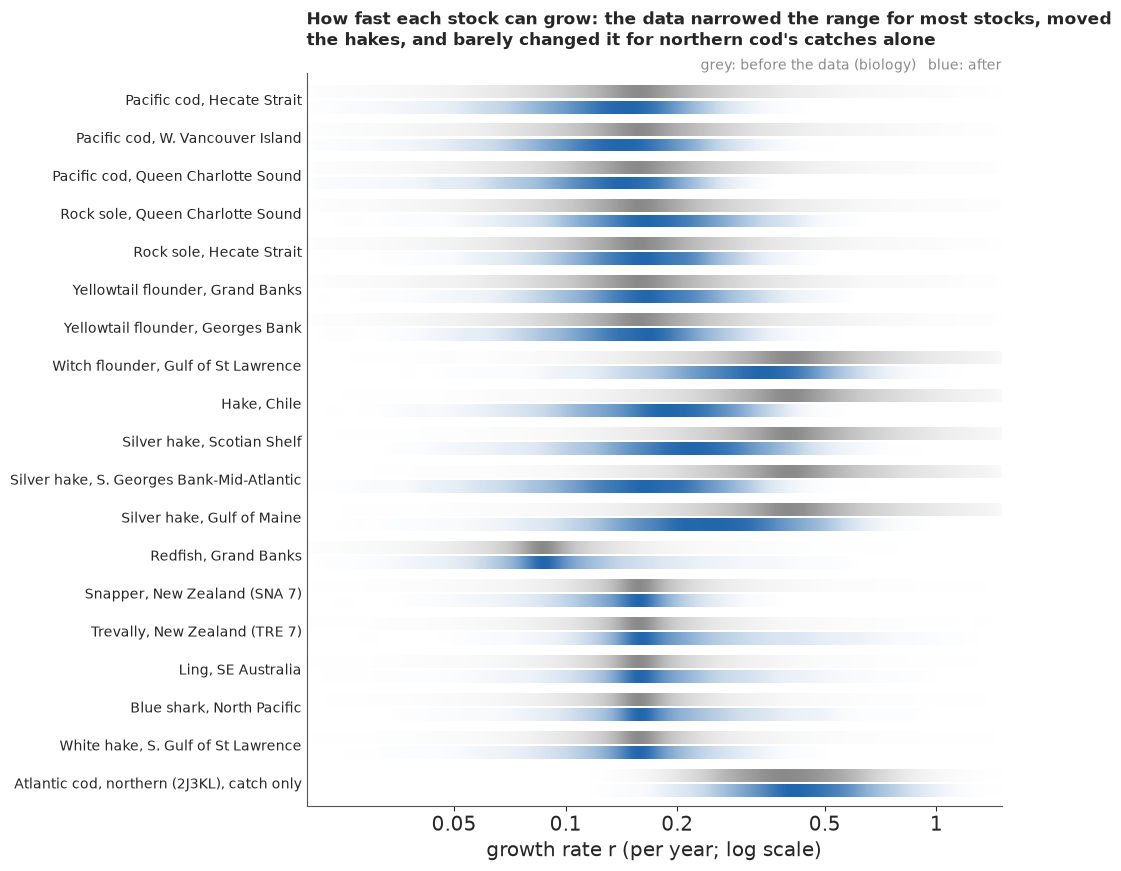

In [28]:
def before_after(ax, rows, xlim=(0.02, 1.5)):  # local: paired gradient strips, log10 r axis
    lx = np.log10(xlim)
    grid = np.linspace(*lx, 301)
    for i, (nm, pr, po) in enumerate(rows):
        y = len(rows) - 1 - i
        for v, c, dy in ((pr, MUTED, 0.2), (po, HI, -0.2)):
            dens = np.histogram(np.log10(v), bins=grid)[0].astype(float)
            dens = np.convolve(dens, np.exp(-0.5 * (np.arange(-15, 16) / 5) ** 2), mode="same")
            img = np.zeros((1, len(dens), 4))
            img[..., :3] = to_rgb(c)
            img[0, :, 3] = (dens / dens.max()) ** 0.8
            ax.imshow(img, extent=(lx[0], lx[1], y + dy - 0.17, y + dy + 0.17), aspect="auto",
                      interpolation="bilinear", origin="lower", zorder=2)
    ax.set_xlim(*lx)
    ax.set_ylim(-0.6, len(rows) - 0.3)
    ax.set_yticks(range(len(rows)), [nm for nm, _, _ in rows][::-1], fontsize=10)
    ax.tick_params(axis="y", length=0)
    tk = [0.05, 0.1, 0.2, 0.5, 1]
    ax.set_xticks(np.log10(tk), [str(t) for t in tk])
    ax.set_xlabel("growth rate r (per year; log scale)")


ba = [(NICE[sid], np.exp(LOGR_PRIOR[sid]), DRAW["r"][:, MAIN.index(sid)]) for sid in MAIN]
ba.append((NICE["COD2J3KL"] + ", catch only", np.exp(pr_rng.normal(DC["m_r"][0], DC["s_r"][0],
                                                                    n_pr)), R_COD))
fig, ax = plt.subplots(figsize=(10, 8.6))
before_after(ax, ba)
ax.text(1.0, 1.0, "grey: before the data (biology)   blue: after", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=10, color=MUTED)
ax.set_title(wrap("How fast each stock can grow: the data narrowed the range for most stocks, "
                  "moved the hakes, and barely changed it for northern cod's catches alone", 80),
             loc="left", fontsize=12.5, pad=20);

The strips repeat the contraction table in a form that needs no table: the blue strip is a little
narrower than the grey for most stocks, clearly shifted for the hakes, and barely changed for
the catch-only cod (contraction about 7%): the catches alone carry a little information, by
ruling out small, slow stocks that could not have survived them, but not much.

### One history at a time

For sharing, the same idea can move. Each frame of the animation is one posterior history of
Pacific cod in Hecate Strait, drawn boldly over the faint earlier frames, so the ensemble builds
up as the reader watches. This is a **hypothetical outcome plot** (Hullman, Resnick & Adar 2015,
*PLOS ONE*; Kale, Nguyen, Kay & Hullman 2019, *IEEE TVCG*): the uncertainty is seen as variation
between frames. At 0.7 s a frame it stays well below the three flashes a second that
accessibility guidance allows.

wrote E114_is_this_fish_overfished_histories.gif: 40 frames, 576x374 px, 1.0 MB
lowest year of the 40 histories: 1999-2002 (middle 80%); 40 of 40 fall below half; above 2 before 1960 in 33; above 4.4 at some point in 10


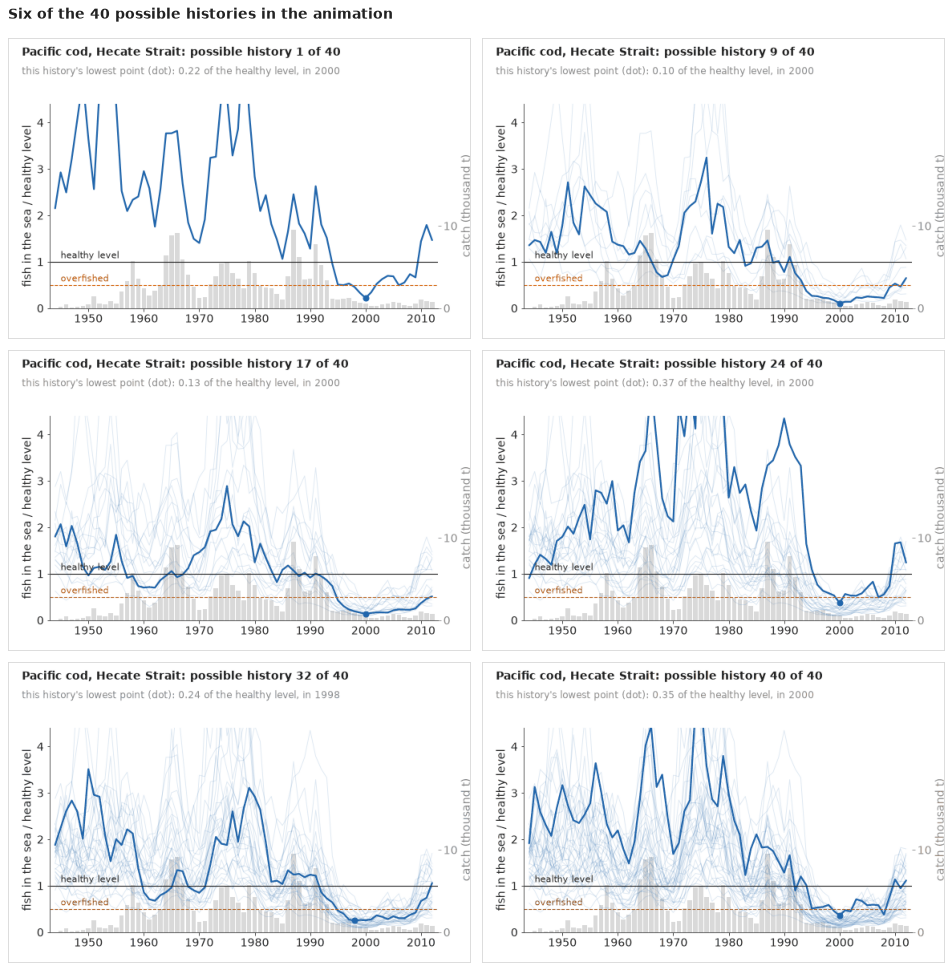

In [29]:
NB_STEM = "E114_is_this_fish_overfished"
GIF = f"{NB_STEM}_histories.gif"  # written next to the notebook: the site copies {stem}*.gif
NF = 40
s_k = MAIN.index("PCODHS")
sel_k = D["st"] == s_k
YK = D["years"][sel_k]
PK = BB[PICK][:, sel_k]
gk = stock_rows("PCODHS")
fig_g = plt.figure(figsize=(8, 5.2), dpi=72, layout="none")
ax_g = fig_g.add_axes([0.09, 0.1, 0.84, 0.68])
ax_c = ax_g.twinx()


def history_frame(k):
    ax_g.clear()
    ax_c.clear()
    ax_c.bar(gk.year, gk.catch_t / 1e3, color=LIGHT, width=0.8, zorder=0)
    ax_c.set_ylim(0, gk.catch_t.max() / 1e3 * 2.6)  # the 10 t tick sits well above the 0.5 line
    ax_c.set_yticks([0, 10])
    ax_c.yaxis.tick_right()
    ax_c.yaxis.set_label_position("right")
    ax_c.set_ylabel("catch (thousand t)", color=MUTED)
    ax_c.tick_params(colors=MUTED)
    ax_c.grid(False)
    ax_g.set_zorder(ax_c.get_zorder() + 1)
    ax_g.patch.set_visible(False)
    for j in range(k):
        ax_g.plot(YK, PK[j], color=HI, alpha=0.15, lw=0.9)
    ax_g.plot(YK, PK[k], color=HI, lw=2.2)
    ax_g.axhline(1, color=INK, lw=1.1)
    ax_g.axhline(0.5, color=LO, lw=1.1, ls="--")
    ax_g.text(1945, 1.03, "healthy level", fontsize=10.5, color=INK, va="bottom")
    ax_g.text(1945, 0.53, "overfished", fontsize=10.5, color=LO, va="bottom")
    i_min = int(np.argmin(PK[k]))
    ax_g.plot(YK[i_min], PK[k, i_min], "o", color=HI, ms=7)
    ax_g.set_xlim(YK[0] - 1, YK[-1] + 1)
    ax_g.set_ylim(0, 4.4)
    ax_g.set_ylabel("fish in the sea / healthy level")
    fig_g.texts.clear()
    fig_g.text(0.03, 0.97, f"Pacific cod, Hecate Strait: possible history {k + 1} of {NF}",
               fontsize=14, color=INK, va="top", weight="bold")
    fig_g.text(0.03, 0.905, f"this history's lowest point (dot): {PK[k, i_min]:.2f} of the healthy "
               f"level, in {YK[i_min]}", fontsize=12, color=MUTED, va="top")


t0 = time.time()
frames = pub.save_gif(fig_g, history_frame, NF, GIF, ms=700)
plt.close(fig_g)
TIMES["GIF"] = time.time() - t0
LOWS = YK[np.argmin(PK, axis=1)]
print(f"lowest year of the 40 histories: {np.quantile(LOWS, 0.1):.0f}-{np.quantile(LOWS, 0.9):.0f} "
      f"(middle 80%); {int((PK < 0.5).any(axis=1).sum())} of {NF} fall below half; above 2 before "
      f"1960 in {int((PK[:, YK < 1960] > 2).any(axis=1).sum())}; above 4.4 at some point in "
      f"{int((PK > 4.4).any(axis=1).sum())}")
fig_cs = pub.gif_contact_sheet(frames, title=f"Six of the {NF} possible histories in the "
                                "animation")
fig_cs.set_dpi(80);

The animation is saved as
[E114_is_this_fish_overfished_histories.gif](E114_is_this_fish_overfished_histories.gif),
small enough for a message or a slide; the six frames above are its static companion, with the
alt text below for screen readers.

![Animated chart of Pacific cod in Hecate Strait, 1944-2012: in each frame one possible history of
the stock size against the healthy level is drawn in bold over the catches; the earlier histories
stay as faint lines. Most histories are high in the 1940s and 1950s, swing through the
1960s-1980s, fall below half the healthy level around 2000 and climb back towards the line by
2012](E114_is_this_fish_overfished_histories.gif)

Most histories share that shape: the story of the stock is clear, its exact path is not. Around
2000 the frames barely change; before the index starts, each new frame puts the stock somewhere
else.

### What the public version gains, and what it costs

The ensemble keeps what the interval plot showed and adds what it lacked: each line is a story
a reader can follow, the dives are counted rather than inferred from a band, and no smooth median
pretends to be the history. It costs precision (no one can read an 89% interval off 40 lines),
and a reader who fixes on the lowest line overstates the risk, which the counted titles are there
to correct. It is only as good as the model behind it: for witch flounder, snapper, rock sole,
Chilean hake and Georges Bank yellowtail, two reasonable analyses disagree.

In [30]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'toy': 8, 'non-centred': 44, 'centred': 3, 'yellowtail alone': 5, '18 stocks, per-stock noise': 53, '18 stocks': 48, 'yellowtail sensitivity': 13, 'northern cod': 7, 'catch-only refits': 8, 'GIF': 6, 'total': 209}


## Summary

- **A one-way trip cannot separate growth from size.** On a simulated stock fished steadily down,
  $\log r$ and $\log K$ sat on a ridge (correlation $-0.99$, $r$ anywhere in 0.1-1.1, 160
  divergences); a recovery after a catch cut narrowed $r$ to 0.33-0.49 around the truth.
- **Centred free states beat non-centring here.** For Pacific cod the non-centred `scan` gave
  r_hat 1.6 and ESS 7; free states sampled in seconds with r_hat about 1.07, the remaining
  divergences at large process noise.
- **Sharing noise and biology across 18 stocks.** Per-stock process noise gave 114 divergences in
  1,000 draws; one shared sd (about 0.24) gave about ten in 4,000 and r_hat at most about 1.02,
  at the cost of ignoring real differences in noise. Growth rates stay mostly prior; the data
  moved the hakes from 0.4 to about 0.2.
- **Against 14 official assessments** the shapes agree well for 7, and the last-year status for 8.
  Five of the six misses are our model being more optimistic, and none of the three officially
  overfished stocks (witch flounder, Georges Bank yellowtail, Chilean hake) is overfished in our
  model. Georges Bank yellowtail's 2014 answer runs from 1.7 to 0.24 times B<sub>MSY</sub> as the
  assumed process sd goes from 0.1 to 0.4.
- **Below the healthy level, and still fished hard?** In the last year of their data (2001-2015)
  about 6 of the 18 stocks (89% range 3-9) were below B<sub>MSY</sub>, and at least 4 very likely
  (94%) were, though we cannot say which; only ling was more likely than not fished above
  F<sub>MSY</sub>. Low confidence: a simple model whose $r$ is mostly prior and which, if
  anything, undercounts.
- **Catches alone mislead.** Catch-only northern cod came out at about twice B<sub>MSY</sub> in
  1992, against an official 5%, with or without a ten-times-lower floor; CMSY's end filter pulled
  2014 down by construction but left 1992 at about 1.5. Three data-rich stocks refitted without
  their index all ended at 1.7-1.8.
- **Ensembles count the dives instead of implying them.** 40 possible histories per stock, with
  counted titles ("40 of 40 fall below half the healthy level in the 1980s"), replace a median and
  band; fish rows, an MSY gradient band, prior-posterior strips and a HOP GIF support them. The
  cost: no interval can be read off the lines, a reader who fixes on the lowest line overstates
  the risk, and tightly bunched lines show the model's certainty, not that it is right (rock
  sole).

## Try it yourself

1. **Pella-Tomlinson.** Replace the logistic surplus with $\frac{r}{m-1} P (1 - P^{m-1})$ and a
   shared shape $m \sim \mathrm{LogNormal}(\log 2, 0.3)$, so that B<sub>MSY</sub> need not be
   half of $K$. Does the agreement with the official levels improve for Hecate Strait rock sole?
2. **Hyperstability.** Commercial catch rates can hold up while a stock shrinks, as they did for
   northern cod. Write the index as $I \propto B^{\beta}$ with $\beta \sim \mathrm{LogNormal}(0,
   0.3)$ for catch-rate series and $\beta = 1$ for surveys, and see which stocks' $\beta$ moves
   below 1.
3. **The small pelagics.** Add South African anchovy and sardine (in the data file as index
   stocks) to the main fit, then give them their own process noise. Do the divergences come back,
   and does a model with a year effect shared by the two (one ocean, two species) fit better?